In [ ]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, zipfile

META_ZIP = "/content/drive/MyDrive/dataset_parts/dataset_small_meta.zip"
META_DIR = "/content/meta"

if not os.path.exists(META_ZIP):
    print("Zip not found. Files in dataset_parts:", os.listdir(os.path.dirname(META_ZIP)))
else:
    with zipfile.ZipFile(META_ZIP) as z:
        print("corrupt member:", z.testzip(), "| files in zip:", sum(not i.is_dir() for i in z.infolist()))
        if not os.path.isdir(META_DIR) or not os.listdir(META_DIR):
            z.extractall(META_DIR)          # python zipfile: no filename-mismatch warnings
    for root, dirs, fs in os.walk(META_DIR):
        if fs: print(f"{root}: {len(fs)} files, e.g. {sorted(fs)[:3]}")

corrupt member: None | files in zip: 25
/content/meta/dataset_small: 1 files, e.g. ['data.yaml']
/content/meta/dataset_small/images/val: 12 files, e.g. ['val_img108.png', 'val_img18.png', 'val_img27.png']
/content/meta/dataset_small/labels/val: 12 files, e.g. ['val_img108.txt', 'val_img18.txt', 'val_img27.txt']


In [ ]:
import numpy as np
from PIL import Image

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
files = [os.path.join(r, f) for r, _, fs in os.walk(META_DIR) for f in fs]
txts = {}
for f in files:
    if f.endswith(".txt"): txts.setdefault(os.path.splitext(os.path.basename(f))[0], []).append(f)

items = []
for f in sorted(files):
    if os.path.splitext(f)[1].lower() in IMG_EXT:
        st = os.path.splitext(os.path.basename(f))[0]
        cand = os.path.splitext(f.replace("/images/", "/labels/"))[0] + ".txt"
        lbl = cand if os.path.exists(cand) else (txts[st][0] if len(txts.get(st, [])) == 1 else None)
        items.append(dict(img=f, lbl=lbl))

def read_labels(lbl):
    rows = []
    if lbl and os.path.exists(lbl):
        for line in open(lbl).read().strip().splitlines():
            p = line.split()
            if len(p) < 5: continue
            v = list(map(float, p[1:]))
            if len(v) == 4: cx, cy, w, h = v
            else:                                            # polygon label -> bbox
                xs, ys = v[0::2], v[1::2]
                cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
            rows.append((0, cx, cy, w, h))                   # single class -> id 0
    return rows

# ---- checks ----
img_stems = {os.path.splitext(os.path.basename(it["img"]))[0] for it in items}
lbl_stems = set(txts)
print(f"images: {len(items)} | label files: {sum(len(v) for v in txts.values())}")
print("images without label:", sorted(img_stems - lbl_stems))
print("label files without image:", sorted(lbl_stems - img_stems))
print("duplicate label stems:", [k for k, v in txts.items() if len(v) > 1])

raw_classes, oob = set(), 0
for it in items:
    if it["lbl"]:
        for line in open(it["lbl"]).read().strip().splitlines():
            p = line.split()
            if p: raw_classes.add(p[0])
    for _, cx, cy, w, h in read_labels(it["lbl"]):
        if cx-w/2 < -0.01 or cx+w/2 > 1.01 or cy-h/2 < -0.01 or cy+h/2 > 1.01: oob += 1
print("class ids found in labels:", raw_classes, "| out-of-bounds boxes:", oob)

TEACH = ["val_img9", "val_img90", "val_img18"]
print("teaching images present:", {t: (t in img_stems) for t in TEACH})

print(f"\n{'file':26} {'size':>10} {'boxes':>6}  role")
for it in items:
    st = os.path.splitext(os.path.basename(it["img"]))[0]
    W, H = Image.open(it["img"]).size
    print(f"{os.path.basename(it['img']):26} {W:>5}x{H:<4} {len(read_labels(it['lbl'])):>6}  {'TEACH' if st in TEACH else 'held-out'}")

images: 12 | label files: 12
images without label: []
label files without image: []
duplicate label stems: []
class ids found in labels: {'0'} | out-of-bounds boxes: 0
teaching images present: {'val_img9': True, 'val_img90': True, 'val_img18': True}

file                             size  boxes  role
val_img108.png              2880x2048     32  held-out
val_img18.png               2880x2048     43  TEACH
val_img27.png               2880x2048     21  held-out
val_img36.png               2880x2048     37  held-out
val_img45.png               2880x2048    143  held-out
val_img54.png               2880x2048     43  held-out
val_img63.png               2880x2048     34  held-out
val_img72.png               2880x2048     39  held-out
val_img81.png               2880x2048     54  held-out
val_img9.png                2880x2048     74  TEACH
val_img90.png               2880x2048     45  TEACH
val_img99.png               2880x2048     21  held-out


In [ ]:
import cv2, matplotlib.pyplot as plt

def draw(it, thick=1):
    img = cv2.cvtColor(cv2.imdecode(np.fromfile(it["img"], np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]; rows = read_labels(it["lbl"])
    for _, cx, cy, w, h in rows:
        cv2.rectangle(img, (int((cx-w/2)*W), int((cy-h/2)*H)), (int((cx+w/2)*W), int((cy+h/2)*H)), (255, 80, 80), thick)
    return img, len(rows)

for page in range(2):
    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    for ax, k in zip(axes.ravel(), range(page*6, page*6 + 6)):
        ax.axis("off")
        if k >= len(items): continue
        it = items[k]; st = os.path.splitext(os.path.basename(it["img"]))[0]
        im, n = draw(it); ax.imshow(im)
        ax.set_title(f"{st} | {n} boxes | {'TEACH' if st in TEACH else 'held-out'}", fontsize=12)
    plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ===== CELL 1: install, mount, unzip ONLY the val (meta) zip, index images + labels =====
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)

from google.colab import drive
drive.mount('/content/drive')
import os, glob, zipfile
import numpy as np
from PIL import Image

META_ZIP = "/content/drive/MyDrive/dataset_parts/dataset_small_meta.zip"
META_DIR = "/content/meta"
if not os.path.isdir(META_DIR) or not os.listdir(META_DIR):
    zipfile.ZipFile(META_ZIP).extractall(META_DIR)          # python zipfile: no filename-mismatch warnings

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
files = [os.path.join(r, f) for r, _, fs in os.walk(META_DIR) for f in fs]
txts = {}
for f in files:
    if f.endswith(".txt"): txts.setdefault(os.path.splitext(os.path.basename(f))[0], []).append(f)

items = []
for f in sorted(files):
    if os.path.splitext(f)[1].lower() in IMG_EXT:
        st = os.path.splitext(os.path.basename(f))[0]
        cand = os.path.splitext(f.replace("/images/", "/labels/"))[0] + ".txt"
        lbl = cand if os.path.exists(cand) else (txts[st][0] if len(txts.get(st, [])) == 1 else None)
        items.append(dict(img=f, lbl=lbl))

def read_labels(lbl):
    rows = []
    if lbl and os.path.exists(lbl):
        for line in open(lbl).read().strip().splitlines():
            p = line.split()
            if len(p) < 5: continue
            v = list(map(float, p[1:]))
            if len(v) == 4: cx, cy, w, h = v
            else:                                            # polygon label -> bbox
                xs, ys = v[0::2], v[1::2]
                cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
            rows.append((0, cx, cy, w, h))                   # single class -> id 0
    return rows

print(f"{'file':28} {'size':>10} {'boxes':>6}")
for it in items:
    W, H = Image.open(it["img"]).size
    print(f"{os.path.basename(it['img']):28} {W:>5}x{H:<4} {len(read_labels(it['lbl'])):>6}")

Mounted at /content/drive
file                               size  boxes
val_img108.png                2880x2048     32
val_img18.png                 2880x2048     43
val_img27.png                 2880x2048     21
val_img36.png                 2880x2048     37
val_img45.png                 2880x2048    143
val_img54.png                 2880x2048     43
val_img63.png                 2880x2048     34
val_img72.png                 2880x2048     39
val_img81.png                 2880x2048     54
val_img9.png                  2880x2048     74
val_img90.png                 2880x2048     45
val_img99.png                 2880x2048     21


In [ ]:
# ===== CELL 2: split 3 teaching / 9 held-out, build tiled + augmented training set =====
import cv2, math, random, shutil, yaml

TEACH = ["val_img9", "val_img90", "val_img18"]
TILE, STRIDE = 1280, 960            # native-resolution 640px tiles (no downscaling), 160px overlap
WORK = "/content/work"
shutil.rmtree(WORK, ignore_errors=True)
random.seed(0); rng = np.random.default_rng(0)

stem = lambda it: os.path.splitext(os.path.basename(it["img"]))[0]
teach_items = [it for it in items if stem(it) in TEACH]
test_items  = [it for it in items if stem(it) not in TEACH]
assert len(teach_items) == 3, f"teaching images not found; available: {[stem(i) for i in items]}"
print("teach:", [stem(i) for i in teach_items]); print("held-out:", len(test_items), "images")

def positions(L, stride):
    if L <= TILE: return [0]
    if stride >= TILE: return list(range(0, L, TILE))                    # exact grid, last tile zero-padded
    n = math.ceil((L - TILE) / stride) + 1
    return sorted(set(np.linspace(0, L - TILE, n).round().astype(int).tolist()))

def make_tiles(img, rows, stride, min_vis=0.5):
    H, W = img.shape[:2]; out = []
    for y0 in positions(H, stride):
        for x0 in positions(W, stride):
            crop = img[y0:y0+TILE, x0:x0+TILE]
            ph, pw = TILE - crop.shape[0], TILE - crop.shape[1]
            if ph or pw: crop = cv2.copyMakeBorder(crop, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=0)
            lab = []
            for _, cx, cy, w, h in rows:
                x1, x2, y1, y2 = (cx-w/2)*W, (cx+w/2)*W, (cy-h/2)*H, (cy+h/2)*H
                ix1, ix2, iy1, iy2 = max(x1, x0), min(x2, x0+TILE), max(y1, y0), min(y2, y0+TILE)
                if ix2 <= ix1 or iy2 <= iy1: continue
                if (ix2-ix1)*(iy2-iy1) < min_vis*(x2-x1)*(y2-y1): continue     # keep boxes >=50% visible in this tile
                lab.append((0, ((ix1+ix2)/2-x0)/TILE, ((iy1+iy2)/2-y0)/TILE, (ix2-ix1)/TILE, (iy2-iy1)/TILE))
            out.append((crop, lab))
    return out

def rot90(img, lab):               # 90 deg counter-clockwise, exact (no box inflation)
    return np.rot90(img).copy(), [(c, cy, 1-cx, h, w) for c, cx, cy, w, h in lab]

def colour_variants(img):          # mimic your gray_ and noisy_ renderings
    g = img.max(axis=2); gray = cv2.merge([g, g, g])
    noisy = np.clip(img.astype(np.float32)*0.7 + rng.normal(8, 8, img.shape), 0, 255).astype(np.uint8)
    return [("c", img), ("g", gray), ("n", noisy)]

def dump(split, name, img, lab):
    for d in ("images", "labels"): os.makedirs(f"{WORK}/{split}/{d}", exist_ok=True)
    cv2.imwrite(f"{WORK}/{split}/images/{name}.png", img)
    open(f"{WORK}/{split}/labels/{name}.txt", "w").write("\n".join(f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for c, cx, cy, w, h in lab))

# --- training tiles: 3 teaching images x tiles x {colour, gray, noisy} x {0, 90 deg}
n_tr = n_box = 0
for it in teach_items:
    img = cv2.imdecode(np.fromfile(it["img"], np.uint8), cv2.IMREAD_COLOR)
    for k, (crop, lab) in enumerate(make_tiles(img, read_labels(it["lbl"]), STRIDE)):
        if not lab and random.random() > 0.2: continue                      # keep only ~20% of empty tiles
        for tag, im in colour_variants(crop):
            for r in (0, 1):
                im2, lab2 = (im, lab) if r == 0 else rot90(im, lab)
                dump("train", f"{stem(it)}_t{k}_{tag}_r{r}", im2, lab2); n_tr += 1; n_box += len(lab2)
print(f"train tiles: {n_tr} | boxes: {n_box}")

# --- held-out: non-overlapping tiles (used as per-epoch val in run B) + full images (used for final evaluation)
n_vt = 0
for it in test_items:
    img = cv2.imdecode(np.fromfile(it["img"], np.uint8), cv2.IMREAD_COLOR)
    rows = read_labels(it["lbl"])
    for k, (crop, lab) in enumerate(make_tiles(img, rows, TILE)):
        if lab: dump("heldout_tiles", f"{stem(it)}_t{k}", crop, lab); n_vt += 1
    dump("heldout_full", stem(it), img, rows)
print("held-out tiles:", n_vt)

sizes = [Image.open(it["img"]).size for it in test_items]
IMGSZ = int(math.ceil(max(max(s) for s in sizes) / 32) * 32)        # full-image inference at native scale
print("held-out image sizes:", set(sizes), "-> full-image imgsz =", IMGSZ)

names = {0: "aggregate"}
yaml.safe_dump(dict(path=WORK, train="train/images", val="heldout_tiles/images", names=names), open(f"{WORK}/tiles.yaml", "w"))
yaml.safe_dump(dict(path=WORK, train="heldout_full/images", val="heldout_full/images", names=names), open(f"{WORK}/full.yaml", "w"))

teach: ['val_img18', 'val_img9', 'val_img90']
held-out: 9 images
train tiles: 102 | boxes: 2160
held-out tiles: 29
held-out image sizes: {(2880, 2048)} -> full-image imgsz = 2880


In [ ]:
# ===== CELL 3: RUN A - train with val=False (no per-epoch validation) =====
from ultralytics import YOLO

AUG = dict(hsv_h=0.02, hsv_s=0.9, hsv_v=0.6, degrees=0, translate=0.15, scale=0.4, shear=0, perspective=0,
           flipud=0.5, fliplr=0.5, mosaic=1.0, mixup=0.1, close_mosaic=15)       # rotation is done offline (exact boxes)
COMMON = dict(data=f"{WORK}/tiles.yaml", imgsz=TILE, epochs=150, batch=16, patience=0, seed=0,
              project="/content/runs", exist_ok=True, workers=2, **AUG)

YOLO("yolo11s.pt").train(name="A_noval", val=False, **COMMON)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/tiles.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=N

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f2a6c397d90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
# ===== CELL 4: RUN B - identical settings, but validate on the held-out tiles after every epoch =====
YOLO("yolo11s.pt").train(name="B_val", val=True, **COMMON)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/tiles.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=No

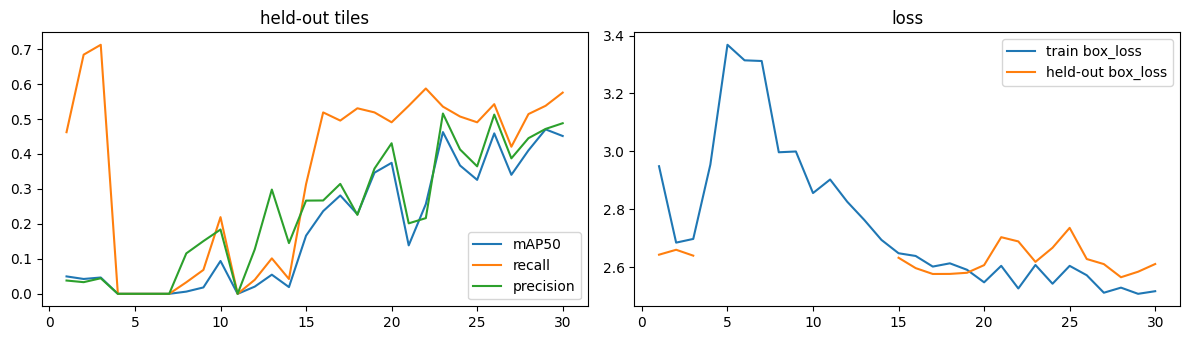

In [ ]:
# ===== CELL B: nano model, 1280 tiles, held-out validation every epoch, saved to Drive, halt anytime =====
import os, shutil, pandas as pd, matplotlib.pyplot as plt
from ultralytics import YOLO

NAME = "B_med1"
PROJECT = "/content/drive/MyDrive/yolo_runs"           # on Drive -> survives runtime disconnects (Drive must be mounted)
RUN_DIR = f"{PROJECT}/{NAME}"
os.makedirs(PROJECT, exist_ok=True)

AUG = dict(hsv_h=0.02, hsv_s=0.9, hsv_v=0.6, degrees=0, translate=0.15, scale=0.4, shear=0, perspective=0,
           flipud=0.5, fliplr=0.5, mosaic=1.0, mixup=0.1, close_mosaic=20)
ARGS = dict(data=f"{WORK}/tiles.yaml", imgsz=TILE, epochs=300, batch=8, patience=300, seed=0,
            project=PROJECT, name=NAME, exist_ok=True, workers=2, val=True, save_period=10, **AUG)

best = {"map50": -1.0}
def keep_best_map50(trainer):                          # called at the end of every epoch
    m = trainer.metrics.get("metrics/mAP50(B)")
    if m is not None and m > best["map50"]:
        best["map50"] = float(m)
        shutil.copy(trainer.last, trainer.wdir / "best_map50.pt")
        print(f"   >> new best held-out mAP50 {m:.3f} at epoch {trainer.epoch + 1} -> best_map50.pt")

def load_results():
    d = pd.read_csv(f"{RUN_DIR}/results.csv"); d.columns = [c.strip() for c in d.columns]; return d

def run(resume=False):
    if resume:
        model = YOLO(f"{RUN_DIR}/weights/last.pt")
        best["map50"] = float(load_results()["metrics/mAP50(B)"].max())
    else:
        model = YOLO("yolov8m.pt")
    model.add_callback("on_fit_epoch_end", keep_best_map50)
    try:
        model.train(resume=True) if resume else model.train(**ARGS)
    except KeyboardInterrupt:
        print("\nHalted by you. last.pt is saved; run(resume=True) continues from it.")

def report():
    d = load_results()
    cols = [c for c in ["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)",
                        "train/box_loss", "val/box_loss"] if c in d.columns]
    print("top epochs by held-out mAP50:")
    print(d[cols].sort_values("metrics/mAP50(B)", ascending=False).head(8).round(3).to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(d["epoch"], d["metrics/mAP50(B)"], label="mAP50"); ax[0].plot(d["epoch"], d["metrics/recall(B)"], label="recall")
    ax[0].plot(d["epoch"], d["metrics/precision(B)"], label="precision"); ax[0].set_title("held-out tiles"); ax[0].legend()
    ax[1].plot(d["epoch"], d["train/box_loss"], label="train box_loss"); ax[1].plot(d["epoch"], d["val/box_loss"], label="held-out box_loss")
    ax[1].set_title("loss"); ax[1].legend(); plt.tight_layout(); plt.show()

# Fresh start if B_nano doesn't exist yet; otherwise it RESUMES the halted run. (To start over, change NAME.)
run(resume=os.path.exists(f"{RUN_DIR}/weights/last.pt"))
report()       # also runs right after you press stop

In [ ]:
# ===== CV-1: choose final-test images, make folds, define tiling helpers (run after the RESTORE cell) =====
import cv2, math, random, shutil, yaml

N_FINAL = 3                  # images kept out of EVERYTHING (teacher + student) for a clean final check; 0 = teacher uses all 12
FINAL_TEST_OVERRIDE = None   # or e.g. ["val_img3", "val_img5", "val_img7"] to choose them yourself
TILE, STRIDE, EPOCHS = 1280, 960, 60
PROJECT = "/content/drive/MyDrive/yolo_runs"
CVROOT = "/content/cv"
os.makedirs(PROJECT, exist_ok=True)

AUG = dict(hsv_h=0.02, hsv_s=0.9, hsv_v=0.6, degrees=0, translate=0.15, scale=0.4, shear=0, perspective=0,
           flipud=0.5, fliplr=0.5, mosaic=1.0, mixup=0.1)

order = list(np.random.default_rng(0).permutation(sorted(stem(it) for it in items)))
final_stems = sorted(FINAL_TEST_OVERRIDE) if FINAL_TEST_OVERRIDE else sorted(order[:N_FINAL])
pool_stems = [s for s in order if s not in final_stems]
pool = [it for it in items if stem(it) in pool_stems]
final_items = [it for it in items if stem(it) in final_stems]
K = max(len(pool) // 3, 2)
folds = [[it for it in pool if stem(it) in pool_stems[i::K]] for i in range(K)]
IMGSZ = int(math.ceil(max(max(Image.open(it["img"]).size) for it in items) / 32) * 32)
print("FINAL TEST (untouched by teacher and student):", final_stems)
for k, f in enumerate(folds): print(f"fold {k}: held-out {[stem(i) for i in f]} | trains on {len(pool) - len(f)} images")
print("full-image inference size:", IMGSZ)

def positions(L, stride):
    if L <= TILE: return [0]
    if stride >= TILE: return list(range(0, L, TILE))
    n = math.ceil((L - TILE) / stride) + 1
    return sorted(set(np.linspace(0, L - TILE, n).round().astype(int).tolist()))

def make_tiles(img, rows, stride, min_vis=0.5):
    H, W = img.shape[:2]; out = []
    for y0 in positions(H, stride):
        for x0 in positions(W, stride):
            crop = img[y0:y0+TILE, x0:x0+TILE]
            ph, pw = TILE - crop.shape[0], TILE - crop.shape[1]
            if ph or pw: crop = cv2.copyMakeBorder(crop, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=0)
            lab = []
            for _, cx, cy, w, h in rows:
                x1, x2, y1, y2 = (cx-w/2)*W, (cx+w/2)*W, (cy-h/2)*H, (cy+h/2)*H
                ix1, ix2, iy1, iy2 = max(x1, x0), min(x2, x0+TILE), max(y1, y0), min(y2, y0+TILE)
                if ix2 <= ix1 or iy2 <= iy1: continue
                if (ix2-ix1)*(iy2-iy1) < min_vis*(x2-x1)*(y2-y1): continue
                lab.append((0, ((ix1+ix2)/2-x0)/TILE, ((iy1+iy2)/2-y0)/TILE, (ix2-ix1)/TILE, (iy2-iy1)/TILE))
            out.append((crop, lab))
    return out

def rot90(img, lab):
    return np.rot90(img).copy(), [(c, cy, 1-cx, h, w) for c, cx, cy, w, h in lab]

def colour_variants(img, rng):
    g = img.max(axis=2); gray = cv2.merge([g, g, g])
    noisy = np.clip(img.astype(np.float32)*0.7 + rng.normal(8, 8, img.shape), 0, 255).astype(np.uint8)
    return [("c", img), ("g", gray), ("n", noisy)]

def dump(root, split, name, img, lab):
    for d in ("images", "labels"): os.makedirs(f"{root}/{split}/{d}", exist_ok=True)
    cv2.imwrite(f"{root}/{split}/images/{name}.png", img)
    open(f"{root}/{split}/labels/{name}.txt", "w").write("\n".join(f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for c, cx, cy, w, h in lab))

def write_full(items_, root):                      # held-out FULL images + yaml (for ultralytics .val)
    shutil.rmtree(f"{root}/heldout_full", ignore_errors=True)
    for it in items_:
        img = cv2.imdecode(np.fromfile(it["img"], np.uint8), cv2.IMREAD_COLOR)
        dump(root, "heldout_full", stem(it), img, read_labels(it["lbl"]))
    yaml.safe_dump(dict(path=root, train="heldout_full/images", val="heldout_full/images", names={0: "aggregate"}), open(f"{root}/full.yaml", "w"))

def build_dataset(train_items, val_items, root):
    shutil.rmtree(root, ignore_errors=True)
    rng, rnd = np.random.default_rng(0), random.Random(0)
    n = 0
    for it in train_items:
        img = cv2.imdecode(np.fromfile(it["img"], np.uint8), cv2.IMREAD_COLOR)
        for k, (crop, lab) in enumerate(make_tiles(img, read_labels(it["lbl"]), STRIDE)):
            if not lab and rnd.random() > 0.2: continue
            for tag, im in colour_variants(crop, rng):
                for r in (0, 1):
                    im2, lab2 = (im, lab) if r == 0 else rot90(im, lab)
                    dump(root, "train", f"{stem(it)}_t{k}_{tag}_r{r}", im2, lab2); n += 1
    for it in val_items:                           # held-out tiles: only used for the (unused) val slot of the yaml
        img = cv2.imdecode(np.fromfile(it["img"], np.uint8), cv2.IMREAD_COLOR)
        for k, (crop, lab) in enumerate(make_tiles(img, read_labels(it["lbl"]), TILE)):
            if lab: dump(root, "heldout_tiles", f"{stem(it)}_t{k}", crop, lab)
    yaml.safe_dump(dict(path=root, train="train/images", val="heldout_tiles/images" if val_items else "train/images",
                        names={0: "aggregate"}), open(f"{root}/tiles.yaml", "w"))
    return n

FINAL TEST (untouched by teacher and student): [np.str_('val_img27'), np.str_('val_img72'), np.str_('val_img9')]
fold 0: held-out ['val_img108', 'val_img45', 'val_img90'] | trains on 6 images
fold 1: held-out ['val_img36', 'val_img54', 'val_img81'] | trains on 6 images
fold 2: held-out ['val_img18', 'val_img63', 'val_img99'] | trains on 6 images
full-image inference size: 2880


In [ ]:
# ===== CV-2: train one nano model per fold (saved to Drive; finished folds are skipped if you rerun) =====
def train_model(name, train_items, val_items, root):
    run = f"{PROJECT}/{name}"
    if os.path.exists(f"{run}/DONE"):
        print(f"[{name}] already finished -> skipped"); return f"{run}/weights/last.pt"
    n = build_dataset(train_items, val_items, root)
    print(f"[{name}] training on {len(train_items)} images -> {n} tiles")
    YOLO("yolo11n.pt").train(data=f"{root}/tiles.yaml", imgsz=TILE, epochs=EPOCHS, batch=8, val=True, patience=0, seed=0,
                             project=PROJECT, name=name, exist_ok=True, workers=2, close_mosaic=10, **AUG)
    open(f"{run}/DONE", "w").write("ok")
    shutil.rmtree(root, ignore_errors=True)        # free disk
    return f"{run}/weights/last.pt"

for k, held in enumerate(folds):
    train_model(f"cv_fold{k}", [it for it in pool if it not in held], held, f"{CVROOT}/fold{k}")

[cv_fold0] training on 6 images -> 168 tiles
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cv/fold0/tiles.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.9, hsv_v=0.6, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cv_fold0, nbs=64, n

In [ ]:
# ===== CV-3: out-of-fold evaluation (every pool image is predicted by a model that never saw it) =====
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import pandas as pd

oof = {}                                           # stem -> predictions [x, y, w, h, conf] in pixels
for k, held in enumerate(folds):
    model = YOLO(f"{PROJECT}/cv_fold{k}/weights/last.pt")
    for it in held:
        r = model.predict(it["img"], imgsz=IMGSZ, conf=0.05, iou=0.6, max_det=300, verbose=False)[0]
        oof[stem(it)] = np.hstack([r.boxes.xywh.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]])
    write_full(held, f"{CVROOT}/evalfold{k}")
    m = model.val(data=f"{CVROOT}/evalfold{k}/full.yaml", imgsz=IMGSZ, batch=1, conf=0.001, iou=0.6, max_det=300, plots=False, verbose=False)
    print(f"fold {k} (full images): mAP50 {m.box.map50:.3f} | P {m.box.mp:.3f} | R {m.box.mr:.3f}")

def score(its, conf):
    tp = fp = fn = 0; pc, gc = [], []
    for it in its:
        W, H = Image.open(it["img"]).size
        rows = read_labels(it["lbl"])
        g = np.array([[cx*W, cy*H] for _, cx, cy, _, _ in rows])
        tol = 0.5 * np.median([(bw*W + bh*H) / 2 for *_, bw, bh in rows])
        pr = oof[stem(it)]; p = pr[pr[:, 4] >= conf][:, :2]
        pc.append(len(p)); gc.append(len(g)); m = 0
        if len(p) and len(g):
            D = cdist(p, g); ri, ci = linear_sum_assignment(D); m = int((D[ri, ci] <= tol).sum())
        tp += m; fp += len(p) - m; fn += len(g) - m
    P, R = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(conf=conf, P=P, R=R, F1=2*P*R / max(P + R, 1e-9), count_MAE=np.mean(np.abs(np.array(pc) - np.array(gc))),
                count_r=np.corrcoef(pc, gc)[0, 1] if len(set(pc)) > 1 else np.nan, pred=sum(pc), manual=sum(gc))

tab = pd.DataFrame([score(pool, c) for c in (0.1, 0.2, 0.3, 0.4, 0.5)]).round(3)
print("\nOUT-OF-FOLD, centre-based (hit = centre within half a box size):"); print(tab.to_string(index=False))
BEST_CONF = float(tab.loc[tab.F1.idxmax(), "conf"]); print("confidence with best F1:", BEST_CONF)
print("\nper image at that confidence (manual vs model count):")
for it in pool:
    print(f"  {stem(it):12} manual {len(read_labels(it['lbl'])):>4} | model {int((oof[stem(it)][:, 4] >= BEST_CONF).sum()):>4}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2827.6±89.9 MB/s, size: 4910.3 KB)
val: Scanning /content/cv/evalfold0/heldout_full/labels... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 142.5it/s 0.0s
val: New cache created: /content/cv/evalfold0/heldout_full/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.0it/s 0.7s
                   all          3        220      0.641      0.559      0.507      0.123
Speed: 25.8ms preprocess, 66.2ms inference, 0.0ms loss, 5.7ms postprocess per image
fold 0 (full images): mAP50 0.507 | P 0.641 | R 0.559
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ 

In [ ]:
# ===== CV-4: final teacher = same recipe, trained on the whole pool (run after you've looked at CV-3) =====
teacher_path = train_model("teacher", pool, [], f"{CVROOT}/teacher")
print("teacher weights:", teacher_path, "| use confidence ~", BEST_CONF)

[teacher] training on 9 images -> 270 tiles
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cv/teacher/tiles.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.9, hsv_v=0.6, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=teacher, nbs=64, n

In [ ]:
# ===== TEACHER CHECK: score the final teacher ONCE on the 3 held-back images (self-contained; works after a restart) =====
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
from google.colab import drive
drive.mount('/content/drive')

import os, math, shutil, zipfile, yaml
import numpy as np, pandas as pd
from PIL import Image
from ultralytics import YOLO
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

META_ZIP = "/content/drive/MyDrive/dataset_parts/dataset_small_meta.zip"
META_DIR = "/content/meta"
TEACHER = "/content/drive/MyDrive/yolo_runs/teacher/weights/last.pt"
N_FINAL = 3                      # must be the same value you used in CV-1
assert os.path.exists(TEACHER), "teacher weights not found on Drive"
if not (os.path.isdir(META_DIR) and os.listdir(META_DIR)):
    zipfile.ZipFile(META_ZIP).extractall(META_DIR)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
files = [os.path.join(r, f) for r, _, fs in os.walk(META_DIR) for f in fs]
txts = {}
for f in files:
    if f.endswith(".txt"): txts.setdefault(os.path.splitext(os.path.basename(f))[0], []).append(f)
items = []
for f in sorted(files):
    if os.path.splitext(f)[1].lower() in IMG_EXT:
        st = os.path.splitext(os.path.basename(f))[0]
        cand = os.path.splitext(f.replace("/images/", "/labels/"))[0] + ".txt"
        items.append(dict(img=f, lbl=cand if os.path.exists(cand) else (txts[st][0] if len(txts.get(st, [])) == 1 else None)))

def read_labels(lbl):
    rows = []
    if lbl and os.path.exists(lbl):
        for line in open(lbl).read().strip().splitlines():
            p = line.split()
            if len(p) < 5: continue
            v = list(map(float, p[1:]))
            if len(v) == 4: cx, cy, w, h = v
            else:
                xs, ys = v[0::2], v[1::2]
                cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
            rows.append((0, cx, cy, w, h))
    return rows

stem = lambda it: os.path.splitext(os.path.basename(it["img"]))[0]
order = list(np.random.default_rng(0).permutation(sorted(stem(it) for it in items)))      # same recipe as CV-1
final_items = [it for it in items if stem(it) in sorted(order[:N_FINAL])]
print("held-back images (must match the names CV-1 printed):", [stem(i) for i in final_items])

IMGSZ = int(math.ceil(max(max(Image.open(it["img"]).size) for it in items) / 32) * 32)
ROOT = "/content/evalfinal"
shutil.rmtree(ROOT, ignore_errors=True)
for d in ("images", "labels"): os.makedirs(f"{ROOT}/heldout_full/{d}", exist_ok=True)
for it in final_items:
    shutil.copy(it["img"], f"{ROOT}/heldout_full/images/{stem(it)}{os.path.splitext(it['img'])[1]}")
    open(f"{ROOT}/heldout_full/labels/{stem(it)}.txt", "w").write(
        "\n".join(f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for c, cx, cy, w, h in read_labels(it["lbl"])))
yaml.safe_dump(dict(path=ROOT, train="heldout_full/images", val="heldout_full/images", names={0: "aggregate"}), open(f"{ROOT}/full.yaml", "w"))

t = YOLO(TEACHER)
m = t.val(data=f"{ROOT}/full.yaml", imgsz=IMGSZ, batch=1, conf=0.001, iou=0.6, max_det=300, plots=False, verbose=False)
print(f"\nteacher on the {len(final_items)} held-back images: mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f} | P {m.box.mp:.3f} | R {m.box.mr:.3f}")

preds = {}
for it in final_items:
    r = t.predict(it["img"], imgsz=IMGSZ, conf=0.05, iou=0.6, max_det=300, verbose=False)[0]
    preds[stem(it)] = np.hstack([r.boxes.xywh.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]])

def score(conf):
    tp = fp = fn = 0; pc, gc = [], []
    for it in final_items:
        W, H = Image.open(it["img"]).size
        rows = read_labels(it["lbl"])
        g = np.array([[cx*W, cy*H] for _, cx, cy, _, _ in rows])
        tol = 0.5 * np.median([(bw*W + bh*H) / 2 for *_, bw, bh in rows])
        pr = preds[stem(it)]; p = pr[pr[:, 4] >= conf][:, :2]
        pc.append(len(p)); gc.append(len(g)); k = 0
        if len(p) and len(g):
            D = cdist(p, g); ri, ci = linear_sum_assignment(D); k = int((D[ri, ci] <= tol).sum())
        tp += k; fp += len(p) - k; fn += len(g) - k
    P, R = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(conf=conf, P=P, R=R, F1=2*P*R / max(P + R, 1e-9), pred=sum(pc), manual=sum(gc))

print("\ncentre-based (hit = centre within half a box size):")
print(pd.DataFrame([score(c) for c in (0.2, 0.3, 0.4)]).round(3).to_string(index=False))
print("\nper image at confidence 0.3 (manual vs model count):")
for it in final_items:
    print(f"  {stem(it):12} manual {len(read_labels(it['lbl'])):>4} | model {int((preds[stem(it)][:, 4] >= 0.3).sum()):>4}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
held-back images (must match the names CV-1 printed): ['val_img27', 'val_img72', 'val_img9']
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1602.0±1376.4 MB/s, size: 3774.1 KB)
val: Scanning /content/evalfinal/heldout_full/labels... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 95.1it/s 0.0s
val: New cache created: /content/evalfinal/heldout_full/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 5.8s/it 17.3s
                   all          3        134      0.736      0.724      0.736      0.196
Speed: 385.3ms preprocess, 5023.9ms inference, 0.0ms loss, 13.6ms postprocess per image

teacher on the 3 held-

In [ ]:
# ===== CV-5: SELF-CONTAINED. Same teacher, the 3 held-back images: whole vs tiles, size, shift, agnostic, conf -> AP30/AP50, P/R =====
# No retraining, no earlier cells needed (works after a restart).
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
from google.colab import drive
drive.mount('/content/drive')

import os, math, shutil, zipfile, yaml, cv2
import numpy as np, pandas as pd
from PIL import Image
from ultralytics import YOLO

META_ZIP = "/content/drive/MyDrive/dataset_parts/dataset_small_meta.zip"
META_DIR = "/content/meta"
TEACHER = "/content/drive/MyDrive/yolo_runs/teacher/weights/last.pt"
N_FINAL = 3                      # same value as in CV-1
assert os.path.exists(TEACHER), "teacher weights not found on Drive"
if not (os.path.isdir(META_DIR) and os.listdir(META_DIR)):
    zipfile.ZipFile(META_ZIP).extractall(META_DIR)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
files = [os.path.join(r, f) for r, _, fs in os.walk(META_DIR) for f in fs]
txts = {}
for f in files:
    if f.endswith(".txt"): txts.setdefault(os.path.splitext(os.path.basename(f))[0], []).append(f)
items = []
for f in sorted(files):
    if os.path.splitext(f)[1].lower() in IMG_EXT:
        st = os.path.splitext(os.path.basename(f))[0]
        cand = os.path.splitext(f.replace("/images/", "/labels/"))[0] + ".txt"
        items.append(dict(img=f, lbl=cand if os.path.exists(cand) else (txts[st][0] if len(txts.get(st, [])) == 1 else None)))

def read_labels(lbl):
    rows = []
    if lbl and os.path.exists(lbl):
        for line in open(lbl).read().strip().splitlines():
            p = line.split()
            if len(p) < 5: continue
            v = list(map(float, p[1:]))
            if len(v) == 4: cx, cy, w, h = v
            else:
                xs, ys = v[0::2], v[1::2]
                cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
            rows.append((0, cx, cy, w, h))
    return rows

stem = lambda it: os.path.splitext(os.path.basename(it["img"]))[0]
order = list(np.random.default_rng(0).permutation(sorted(stem(it) for it in items)))      # same recipe as CV-1
final_items = [it for it in items if stem(it) in sorted(order[:N_FINAL])]
print("held-back images (must match the names CV-1 printed):", [stem(i) for i in final_items])
IMGSZ = int(math.ceil(max(max(Image.open(it["img"]).size) for it in items) / 32) * 32)

ROOT = "/content/evalfinal"
shutil.rmtree(ROOT, ignore_errors=True)
for d in ("images", "labels"): os.makedirs(f"{ROOT}/heldout_full/{d}", exist_ok=True)
for it in final_items:
    shutil.copy(it["img"], f"{ROOT}/heldout_full/images/{stem(it)}{os.path.splitext(it['img'])[1]}")
    open(f"{ROOT}/heldout_full/labels/{stem(it)}.txt", "w").write(
        "\n".join(f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for c, cx, cy, w, h in read_labels(it["lbl"])))
yaml.safe_dump(dict(path=ROOT, train="heldout_full/images", val="heldout_full/images", names={0: "aggregate"}), open(f"{ROOT}/full.yaml", "w"))

model = YOLO(TEACHER)
m = model.val(data=f"{ROOT}/full.yaml", imgsz=IMGSZ, batch=1, conf=0.001, iou=0.6, max_det=300, plots=False, verbose=False)
print(f"ultralytics .val, WHOLE images imgsz={IMGSZ}: mAP50 {m.box.map50:.3f} | P {m.box.mp:.3f} | R {m.box.mr:.3f}   <- compare with your 73%")

WHOLE  = (2304, 2880, 3456, 4096)     # whole-image imgsz (long side). 2880 = native
TILES  = (960, 1280, 1920)            # tile edge in native px (training used 1280)
UPS    = (1.0, 1.25)                  # tile is resized to edge*UP before the network (1.0 = native scale)
SHIFTS = ((0, 0), (0.5, 0.5))         # tile-grid shift as a fraction of the stride; both are also run merged
AGN    = (False, True)                # agnostic_nms (identical results with one class, here only to show it)
OVERLAP, NMS_IOU, CONF_MIN = 0.25, 0.6, 0.001
CONF_FLOORS = (0.001, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5)
THRS = [0.30] + [round(0.5 + 0.05 * i, 2) for i in range(10)]          # 0.30, 0.50 ... 0.95
J30, J50 = 0, 1

imgs = {stem(it): cv2.imdecode(np.fromfile(it["img"], np.uint8), cv2.IMREAD_COLOR) for it in final_items}
gts = {}
for it in final_items:
    H, W = imgs[stem(it)].shape[:2]
    gts[stem(it)] = np.array([[(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H] for _, cx, cy, w, h in read_labels(it["lbl"])]).reshape(-1, 4)

def box_iou(a, b):
    if not len(a) or not len(b): return np.zeros((len(a), len(b)))
    iw = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    ih = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = iw * ih; ar = lambda x: (x[:, 2]-x[:, 0]) * (x[:, 3]-x[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)

def nms(b, thr):                                           # rows: x1, y1, x2, y2, conf
    if len(b) == 0: return b
    b = b[np.argsort(-b[:, 4])]; ar = (b[:, 2]-b[:, 0]) * (b[:, 3]-b[:, 1]); idx = np.arange(len(b)); keep = []
    while idx.size:
        i = idx[0]; keep.append(i); r = idx[1:]
        if not r.size: break
        inter = np.clip(np.minimum(b[i, 2], b[r, 2]) - np.maximum(b[i, 0], b[r, 0]), 0, None) * \
                np.clip(np.minimum(b[i, 3], b[r, 3]) - np.maximum(b[i, 1], b[r, 1]), 0, None)
        idx = r[inter / (ar[i] + ar[r] - inter + 1e-9) <= thr]
    return b[keep]

def predict(arrs, imgsz, ag, chunk):
    out = []
    for i in range(0, len(arrs), chunk):
        part = arrs[i:i+chunk]
        for r in model.predict(part, imgsz=imgsz, batch=len(part), conf=CONF_MIN, iou=0.7, max_det=1000, agnostic_nms=ag, verbose=False):
            out.append(np.hstack([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]]))
    return out

def starts(L, T, stride, off):                             # tile origins along one axis (last tile reaches the far edge)
    xs = [-off]
    while xs[-1] + T < L: xs.append(xs[-1] + stride)
    return xs

def infer(img, tile, size, frac, ag):                      # tile=None -> whole image at imgsz=size
    H, W = img.shape[:2]
    if tile is None: return predict([img], size, ag, 1)[0]
    stride = int(tile * (1 - OVERLAP)); ox, oy = int(round(frac[0]*stride)), int(round(frac[1]*stride))
    org = [(x, y) for y in starts(H, tile, stride, oy) for x in starts(W, tile, stride, ox)]
    crops = []
    for x0, y0 in org:                                     # black padding where a tile leaves the image (as in training tiles)
        c = np.zeros((tile, tile, 3), img.dtype); xa, ya, xb, yb = max(x0, 0), max(y0, 0), min(x0+tile, W), min(y0+tile, H)
        c[ya-y0:yb-y0, xa-x0:xb-x0] = img[ya:yb, xa:xb]; crops.append(c)
    out = []
    for (x0, y0), b in zip(org, predict(crops, size, ag, 8)):
        b = b.copy(); bad = np.zeros(len(b), bool)         # drop boxes cut by an interior tile border; the overlapping tile sees them whole
        if x0 > 0: bad |= b[:, 0] <= 2
        if y0 > 0: bad |= b[:, 1] <= 2
        if x0 + tile < W: bad |= b[:, 2] >= tile - 2
        if y0 + tile < H: bad |= b[:, 3] >= tile - 2
        b = b[~bad]; b[:, [0, 2]] = (b[:, [0, 2]] + x0).clip(0, W); b[:, [1, 3]] = (b[:, [1, 3]] + y0).clip(0, H)
        out.append(b[(b[:, 2]-b[:, 0] > 1) & (b[:, 3]-b[:, 1] > 1)])
    return np.vstack(out) if out else np.zeros((0, 5))

def prep(preds):                                           # TP flags at every IoU threshold, greedy match by confidence
    cs, ts, n_gt = [], [], 0
    for s, P in preds.items():
        G = gts[s]; n_gt += len(G)
        if not len(P): continue
        P = P[np.argsort(-P[:, 4])]; iou = box_iou(P[:, :4], G); tp = np.zeros((len(P), len(THRS)), bool)
        for j, t in enumerate(THRS):
            used = np.zeros(len(G), bool)
            for i in np.where((iou >= t).any(1))[0]:
                ok = (iou[i] >= t) & ~used
                if ok.any(): g = np.where(ok)[0][iou[i][ok].argmax()]; used[g] = True; tp[i, j] = True
        cs.append(P[:, 4]); ts.append(tp)
    return dict(conf=np.concatenate(cs) if cs else np.zeros(0), tp=np.vstack(ts) if ts else np.zeros((0, len(THRS)), bool), n=n_gt)

def ap(conf, tp, n):
    if not len(conf) or n == 0: return 0.0
    t = tp[np.argsort(-conf)]; c = np.cumsum(t); f = np.cumsum(~t)
    mr = np.concatenate(([0.0], c / n, [1.0])); mp = np.concatenate(([1.0], c / (c + f), [0.0]))
    mp = np.flip(np.maximum.accumulate(np.flip(mp))); x = np.linspace(0, 1, 101)
    return float((getattr(np, "trapezoid", None) or np.trapz)(np.interp(x, mr, mp), x))

def pr(E, j, c):                                           # precision, recall when only conf >= c is kept
    sel = E["conf"] >= c; k = int(sel.sum()); tp = int(E["tp"][sel, j].sum())
    return (tp / k if k else 0.0), (tp / E["n"] if E["n"] else 0.0), k

def metrics(E, floor=0.0):
    sel = E["conf"] >= floor; a = [ap(E["conf"][sel], E["tp"][sel][:, j], E["n"]) for j in range(len(THRS))]
    d = {"AP30": a[J30], "AP50": a[J50], "mAP50-95": float(np.mean(a[1:]))}
    for j, nm in ((J30, "30"), (J50, "50")):               # P/R at the confidence with the best F1
        best = max(((*pr(E, j, c), c) for c in np.linspace(0.01, 0.95, 95)), key=lambda z: 2*z[0]*z[1] / max(z[0]+z[1], 1e-9))
        d.update({f"P{nm}": best[0], f"R{nm}": best[1], f"conf{nm}": round(float(best[3]), 2)})
    return d

# ---- run all settings ----
settings = [("whole", None, s, (0, 0), ag) for s in WHOLE for ag in AGN]
for T in TILES:
    for up in UPS:
        for sh in list(SHIFTS) + ["both"]:
            for ag in AGN: settings.append((f"tile{T} x{up}", T, int(round(T*up/32)*32), sh, ag))
cache, EV, rows = {}, {}, []
def raw(s, tile, size, frac, ag):
    k = (s, tile, size, frac, ag)
    if k not in cache: cache[k] = infer(imgs[s], tile, size, frac, ag)
    return cache[k]
for name, tile, size, sh, ag in settings:
    fr = list(SHIFTS) if sh == "both" else [sh]
    try: preds = {s: nms(np.vstack([raw(s, tile, size, f, ag) for f in fr]), NMS_IOU) for s in imgs}
    except RuntimeError as e: print("skipped (probably GPU memory):", name, size); continue
    key = f"{name} | net {size}px | shift {sh if tile else '-'} | agnostic {ag}"
    EV[key] = prep(preds); rows.append(dict(setting=key, **metrics(EV[key])))
res = pd.DataFrame(rows)
base = res[res.setting.str.startswith("whole | net 2880") & res.setting.str.endswith("False")].iloc[0]
res["dAP50"] = res.AP50 - base.AP50
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
cols = ["setting", "AP30", "AP50", "mAP50-95", "dAP50", "P30", "R30", "conf30", "P50", "R50", "conf50"]
print("\nBASELINE = whole image, native 2880 (P/R are at the best-F1 confidence for that IoU)")
print(res[res.setting == base.setting][cols].round(3).to_string(index=False))
print("\nTOP 15 SETTINGS by AP50 (all", len(res), "are in the DataFrame `res`)"); print(res.sort_values("AP50", ascending=False).head(15)[cols].round(3).to_string(index=False))

# ---- metric vs confidence threshold: baseline and the best setting ----
best = res.sort_values("AP50", ascending=False).iloc[0].setting
crow = []
for k in dict.fromkeys([base.setting, best]):
    for f in CONF_FLOORS:
        d = metrics(EV[k], f); p3, r3, n = pr(EV[k], J30, f); p5, r5, _ = pr(EV[k], J50, f)
        crow.append(dict(setting=k.split(" | agnostic")[0], conf=f, AP30=d["AP30"], AP50=d["AP50"], P30=p3, R30=r3, P50=p5, R50=r5, n_pred=n, n_gt=EV[k]["n"]))
print("\nMETRICS vs CONFIDENCE (AP uses only predictions >= conf; P/R are measured at that conf)")
print(pd.DataFrame(crow).round(3).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
held-back images (must match the names CV-1 printed): ['val_img27', 'val_img72', 'val_img9']
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2839.7±138.2 MB/s, size: 3774.1 KB)
val: Scanning /content/evalfinal/heldout_full/labels... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 163.8it/s 0.0s
val: New cache created: /content/evalfinal/heldout_full/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.2s/it 12.5s
                   all          3        134      0.736      0.724      0.736      0.196
Speed: 48.5ms preprocess, 3968.4ms inference, 0.0ms loss, 6.6ms postprocess per image
ultralytics .val, WHOLE i

In [ ]:
# ===== CELL 5: compare both runs on the 9 held-out FULL images (native scale) =====
from ultralytics import YOLO
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import pandas as pd

MODELS = {"A_noval (last)": "/content/runs/A_noval/weights/last.pt",
          "B_val (last)":   "/content/runs/B_val/weights/last.pt",
          "B_val (best*)":  "/content/runs/B_val/weights/best.pt"}      # *best.pt was picked using these same 9 images -> optimistic
MODELS = {k: v for k, v in MODELS.items() if os.path.exists(v)}
CONFS = (0.15, 0.25, 0.4)

def ultra_eval(w):                  # standard YOLO metrics (P/R at the best-F1 confidence, mAP over all confidences)
    m = YOLO(w).val(data=f"{WORK}/full.yaml", imgsz=IMGSZ, batch=4, conf=0.001, iou=0.6, max_det=300, plots=False, verbose=False)
    return dict(P=m.box.mp, R=m.box.mr, mAP50=m.box.map50, mAP50_95=m.box.map)

def centre_eval(w, conf):           # forgiving metric: hit = predicted centre within half a box-size of a manual centre
    model = YOLO(w); tp = fp = fn = 0; pc, gc = [], []
    for it in test_items:
        W, H = Image.open(it["img"]).size
        rows = read_labels(it["lbl"])
        g = np.array([[cx*W, cy*H] for _, cx, cy, _, _ in rows])
        tol = 0.5 * np.median([(bw*W + bh*H) / 2 for *_, bw, bh in rows])
        r = model.predict(it["img"], imgsz=IMGSZ, conf=conf, iou=0.6, max_det=300, verbose=False)[0]
        p = r.boxes.xywh.cpu().numpy()[:, :2]
        pc.append(len(p)); gc.append(len(g))
        m = 0
        if len(p) and len(g):
            D = cdist(p, g); ri, ci = linear_sum_assignment(D); m = int((D[ri, ci] <= tol).sum())
        tp += m; fp += len(p) - m; fn += len(g) - m
    P, R = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(conf=conf, P=P, R=R, F1=2*P*R / max(P + R, 1e-9), count_MAE=np.mean(np.abs(np.array(pc) - np.array(gc))),
                count_r=np.corrcoef(pc, gc)[0, 1] if len(set(pc)) > 1 else np.nan, pred_total=sum(pc), gt_total=sum(gc))

print("== YOLO metrics on 9 held-out images ==")
print(pd.DataFrame({k: ultra_eval(v) for k, v in MODELS.items()}).T.round(3))
print("\n== centre-based metrics (hit = centre within half a box size) ==")
print(pd.DataFrame([dict(model=k, **centre_eval(v, c)) for k, v in MODELS.items() for c in CONFS]).round(3).to_string(index=False))

In [ ]:
# ===== LABEL: run the teacher on all train images (native scale), write YOLO labels at 3 confidence thresholds, zip everything =====
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
from google.colab import drive
drive.mount('/content/drive')

import os, io, re, glob, math, time, zipfile, pickle, shutil
import numpy as np, pandas as pd, cv2
from PIL import Image
from ultralytics import YOLO
import torch

TEACHER   = "/content/drive/MyDrive/yolo_runs/teacher/weights/last.pt"
SRC       = "/content/drive/MyDrive/dataset_parts"
RAW       = "/content/drive/MyDrive/relabel_v2/raw"                 # raw predictions per source zip (makes the run resumable)
ZIP_LOCAL = "/content/yolo_labelled_dataset.zip"
ZIP_DRIVE = "/content/drive/MyDrive/yolo_labelled_dataset.zip"
THRESHOLDS = (0.05, 0.20, 0.40)         # one label folder per threshold
INCLUDE_IMAGES = True                   # False -> the zip holds only the label folders (small; images stay in your original zips)
NMS_IOU, MAX_DET, CHUNK, ALLOW_CPU = 0.6, 1000, 4, False
CONF_FLOOR = min(THRESHOLDS)
ROOTN = "yolo_labelled_dataset"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

assert os.path.exists(TEACHER), "teacher weights not found"
if not ALLOW_CPU: assert torch.cuda.is_available(), "No GPU: switch the runtime to a GPU (CPU would take ~5 hours)."
zips = sorted(glob.glob(f"{SRC}/dataset_small_train_part*.zip"))
print("train zips:", [os.path.basename(z) for z in zips])

def image_members(zf):
    return [i for i in zf.infolist() if not i.is_dir() and os.path.splitext(i.filename)[1].lower() in IMG_EXT
            and "__MACOSX" not in i.filename and not os.path.basename(i.filename).startswith(".")]

names_all = [os.path.basename(i.filename) for z in zips for i in image_members(zipfile.ZipFile(z))]
DUP = len(names_all) != len(set(names_all))
print(f"{len(names_all)} images | filename collisions across zips: {DUP}" + ("  -> files get a pNN_ prefix" if DUP else "  -> original names kept"))
def out_name(zi, member):
    b = os.path.basename(member); return f"p{zi+1:02d}_{b}" if DUP else b

# ---------- stage A: inference (resumable per zip; existing labels in the zips are ignored) ----------
model = YOLO(TEACHER); os.makedirs(RAW, exist_ok=True)
for zi, z in enumerate(zips):
    name = os.path.splitext(os.path.basename(z))[0]; pkl = f"{RAW}/{name}.pkl"
    if os.path.exists(pkl): print(f"[{name}] predictions already saved -> skipped"); continue
    zf = zipfile.ZipFile(z); mem = image_members(zf); res, pending, t0 = {}, {}, time.time()
    def flush(size, items):
        sz = int(math.ceil(max(size) / 32) * 32); arrs = [a for _, a in items]          # native scale: long side not resized
        try: out = model.predict(arrs, imgsz=sz, conf=CONF_FLOOR, iou=NMS_IOU, max_det=MAX_DET, verbose=False)
        except RuntimeError:                                                            # GPU memory: one image at a time
            out = [model.predict(a, imgsz=sz, conf=CONF_FLOOR, iou=NMS_IOU, max_det=MAX_DET, verbose=False)[0] for a in arrs]
        for (key, _), r in zip(items, out):
            res[key] = dict(size=size, pred=np.hstack([r.boxes.xywhn.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]]).astype(np.float32))
    for info in mem:
        a = cv2.imdecode(np.frombuffer(zf.read(info), np.uint8), cv2.IMREAD_COLOR)
        if a is None: print("   could not decode:", info.filename); continue
        size = (a.shape[1], a.shape[0]); pending.setdefault(size, []).append((info.filename, a))
        if len(pending[size]) == CHUNK:
            flush(size, pending.pop(size))
            if len(res) % 200 < CHUNK: print(f"   [{name}] {len(res)}/{len(mem)} | {(time.time()-t0)/len(res):.2f}s/img")
    for size, items in pending.items(): flush(size, items)
    pickle.dump(res, open(pkl, "wb")); print(f"[{name}] {len(res)} images done, sizes: { {s: sum(v['size']==s for v in res.values()) for s in set(v['size'] for v in res.values())} }")

# ---------- stage B: write labels at each threshold + pack the zip ----------
raw = {}
for zi, z in enumerate(zips):
    for k, v in pickle.load(open(f"{RAW}/{os.path.splitext(os.path.basename(z))[0]}.pkl", "rb")).items(): raw[(zi, k)] = v
label_dirs = {t: f"labels_conf{t:.2f}" for t in THRESHOLDS}

def label_text(pred, t):                                         # YOLO format: class cx cy w h (normalized). NO confidence column.
    P = np.clip(pred[pred[:, 4] >= t][:, :4], 0, 1)
    return "".join(f"0 {a:.6f} {b:.6f} {c:.6f} {d:.6f}\n" for a, b, c, d in P)

README = f"""Teacher-labelled YOLO dataset (single class: 0 = aggregate). Existing automated labels were NOT used.
images/train/<name>            : the {len(raw)} train images{'' if INCLUDE_IMAGES else ' (NOT included in this zip)'}
""" + "".join(f"{d}/train/<name>.txt : teacher boxes with confidence >= {t:.2f}\n" for t, d in label_dirs.items()) + """
Ultralytics finds labels by replacing '/images/' with '/labels/' in each image path. To train with one label set, build a folder
with a real images/train directory of symlinks to the images and a 'labels' directory that is a copy/symlink of the chosen label folder.
Labels are model predictions (no confidence column); the same image has an (possibly empty) .txt in every label folder.
"""
n_files = 1
with zipfile.ZipFile(ZIP_LOCAL, "w", zipfile.ZIP_STORED) as out:
    out.writestr(f"{ROOTN}/README.txt", README)
    for zi, z in enumerate(zips):
        zf = zipfile.ZipFile(z)
        for info in image_members(zf):
            rec = raw.get((zi, info.filename))
            if rec is None: continue
            oname = out_name(zi, info.filename); st = os.path.splitext(oname)[0]
            if INCLUDE_IMAGES: out.writestr(f"{ROOTN}/images/train/{oname}", zf.read(info)); n_files += 1
            for t, d in label_dirs.items(): out.writestr(f"{ROOTN}/{d}/train/{st}.txt", label_text(rec["pred"], t)); n_files += 1
print(f"zip written locally: {os.path.getsize(ZIP_LOCAL)/1e9:.2f} GB, {n_files} files. Copying to Drive...")
shutil.copy(ZIP_LOCAL, ZIP_DRIVE); print("saved:", ZIP_DRIVE, f"({os.path.getsize(ZIP_DRIVE)/1e9:.2f} GB)")

# ---------- summary ----------
def kind_of(s):
    m = re.match(r"^(.*?)img\d+$", s); pre = m.group(1) if m else s
    return "orig" if pre.startswith("orig") else ("rotated" if re.match(r"^\d+\D", pre) else (pre.strip("_") or "?"))
rows = [dict(kind=kind_of(os.path.splitext(os.path.basename(k))[0]), **{f"conf>={t:.2f}": int((v["pred"][:, 4] >= t).sum()) for t in THRESHOLDS})
        for (zi, k), v in raw.items()]
df = pd.DataFrame(rows)
print("\nimage sizes:", pd.Series([v["size"] for v in raw.values()]).value_counts().to_dict())
print("\nMEAN BOXES PER IMAGE")
print(pd.concat([df.drop(columns="kind").mean().rename("ALL").to_frame().T, df.groupby("kind").mean(numeric_only=True)]).round(1)
        .assign(n_images=[len(df)] + df.groupby("kind").size().tolist()).to_string())
hi = f"conf>={max(THRESHOLDS):.2f}"; print(f"images with ZERO boxes at {hi}: {(df[hi] == 0).mean():.1%}")

def manual_median_px(meta_zip=f"{SRC}/dataset_small_meta.zip"):    # box size of your 12 manual images, read from the meta zip
    z = zipfile.ZipFile(meta_zip); names = z.namelist(); sz = []
    for n in names:
        if n.endswith(".txt"):
            s = os.path.splitext(os.path.basename(n))[0]
            im = [m for m in names if os.path.splitext(os.path.basename(m))[0] == s and os.path.splitext(m)[1].lower() in (".png", ".jpg", ".jpeg")]
            if not im: continue
            W, H = Image.open(io.BytesIO(z.read(im[0]))).size
            for line in z.read(n).decode().strip().splitlines():
                p = line.split()
                if len(p) >= 5: sz.append((float(p[3]) * W, float(p[4]) * H))
    return np.median(np.array(sz), 0), len(sz)
try:
    mm, n_m = manual_median_px()
    tb = [np.median(v["pred"][v["pred"][:, 4] >= max(THRESHOLDS)][:, 2:4] * v["size"], 0) for v in raw.values() if (v["pred"][:, 4] >= max(THRESHOLDS)).any()]
    tm = np.median(np.array(tb), 0)
    print(f"\nSCALE CHECK, median box w x h in px: manual val labels ({n_m} boxes) {mm[0]:.0f} x {mm[1]:.0f} | teacher boxes on train images {tm[0]:.0f} x {tm[1]:.0f}"
          "\n  -> if these differ by more than ~1.5x, the train images are at a different magnification than the manual ones: tell me before training.")
except Exception as e: print("scale check skipped:", e)

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
train zips: ['dataset_small_train_part01.zip', 'dataset_small_train_part02.zip', 'dataset_small_train_part03.zip', 'dataset_small_train_part04.zip', 'dataset_small_train_part05.zip']
5000 images | filename collisions across zips: False  -> original names kept
   [dataset_small_train_part01] 200/1000 | 0.14s/img
   [dataset_small_train_part01] 400/1000 | 0.11s/img
   [dataset_small_train_part01] 600/1000 | 0.10s/img
   [dataset_small_train_part01] 800/1000 | 0.10s/img
[dataset_small_train_part01] 1000 images done, sizes: {(1440, 1024): 734, (2880, 2048): 266}
   [dataset_small_train_part02] 200/1000 | 0.08s/img
   [dataset_small_train_part02] 400/1000 | 0.07s/img
   [dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, pickle, zipfile

RAW = "/content/drive/MyDrive/relabel_v2/raw"
n_images = 0
for p in sorted(glob.glob(f"{RAW}/*.pkl")):
    try:
        d = pickle.load(open(p, "rb")); n_images += len(d); print(f"OK      {os.path.basename(p)}: {len(d)} images")
    except Exception as e:
        print(f"BROKEN  {os.path.basename(p)} ({type(e).__name__}) -> deleting it so it gets redone"); os.remove(p)
print("zips with saved predictions:", len(glob.glob(f"{RAW}/*.pkl")), "of", len(glob.glob("/content/drive/MyDrive/dataset_parts/dataset_small_train_part*.zip")))

Z = "/content/drive/MyDrive/yolo_labelled_dataset.zip"
if os.path.exists(Z):
    try:
        n = len(zipfile.ZipFile(Z).namelist())
        print(f"final zip opens fine: {n} entries, {os.path.getsize(Z)/1e9:.2f} GB "
              f"(complete = {n_images * 4 + 1} entries with images, {n_images * 3 + 1} labels-only)")
    except zipfile.BadZipFile:
        print("final zip is incomplete (the copy was cut off) -> rerunning the labelling cell rebuilds it")
else:
    print("final zip is not on Drive yet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK      dataset_small_train_part01.pkl: 1000 images
OK      dataset_small_train_part02.pkl: 1000 images
OK      dataset_small_train_part03.pkl: 1000 images
OK      dataset_small_train_part04.pkl: 1000 images
OK      dataset_small_train_part05.pkl: 1000 images
zips with saved predictions: 5 of 5
final zip opens fine: 20001 entries, 8.39 GB (complete = 20001 entries with images, 15001 labels-only)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
held-back images (not opened anywhere in this cell): [np.str_('val_img27'), np.str_('val_img72'), np.str_('val_img9')]
   cutting tiles: 0/2791 images
   cutting tiles: 500/2791 images
   cutting tiles: 1000/2791 images
   cutting tiles: 1500/2791 images
   cutting tiles: 2000/2791 images
   cutting tiles: 2500/2791 images
train: 5000 images in zip | excluded noisy: 653 | no label file: 0 | tiles: 4000 | boxes/tile mean 10.9 | empty tiles 6%
val: 9 pool images -> 37 tiles, 451 manual boxes

training student_conf0.20: 30 epochs x ~333 steps
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=12, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compi

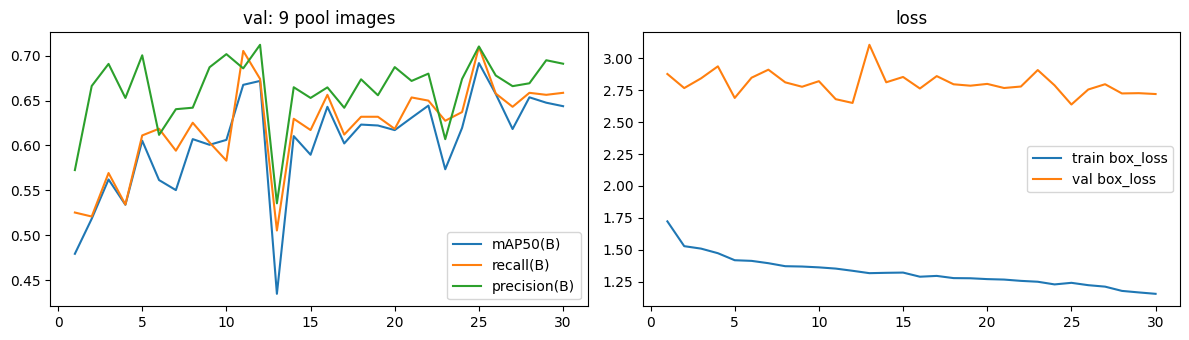


Done. Weights: /content/drive/MyDrive/yolo_runs/student_conf0.20/weights/best_map50.pt and last.pt. The 3 held-back images have not been touched.


In [ ]:
# ===== STUDENT: tile-based training on teacher labels; per-epoch val on the 9 pool images (as tiles); Drive-saved; halt/resume anytime =====
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
from google.colab import drive
drive.mount('/content/drive')

import os, re, io, math, struct, zipfile, shutil, random, yaml
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------------- settings ----------------
LABEL_SET   = "labels_conf0.20"                    # which label folder of the zip to train on
DATASET_ZIP = "/content/drive/MyDrive/yolo_labelled_dataset.zip"
META_ZIP    = "/content/drive/MyDrive/dataset_parts/dataset_small_meta.zip"
PROJECT     = "/content/drive/MyDrive/yolo_runs"
NAME        = f"student_{LABEL_SET.replace('labels_', '')}"      # e.g. student_conf0.20
TILE        = 1024                                 # native-scale tile edge (train AND val use the same size)
MAX_TILES   = 4000                                 # random sample of the training tiles (the 5k images are ~50 copies of ~98 sources)
EPOCHS, BATCH = 30, 12
EXCLUDE_NOISY = True                               # drop noisy_* images: the teacher finds only ~half (noisy_gray: ~none) of their aggregates
KEEP_EMPTY  = 0.2                                  # fraction of tiles with no boxes that are kept as background
N_FINAL     = 3                                    # held-back images: never opened by this cell
EXPECTED_FINAL = ["val_img27", "val_img72", "val_img9"]
ROOT = f"/content/student_{LABEL_SET}"
RUN_DIR = f"{PROJECT}/{NAME}"
assert torch.cuda.is_available(), "Switch the runtime to a GPU."
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ---------------- the 12 manual images: 9 pool -> per-epoch val, 3 held-back -> untouched ----------------
mz = zipfile.ZipFile(META_ZIP); mn = mz.namelist()
stem_of = lambda n: os.path.splitext(os.path.basename(n))[0]
meta_imgs = {stem_of(n): n for n in mn if os.path.splitext(n)[1].lower() in IMG_EXT}
meta_lbls = {stem_of(n): n for n in mn if n.endswith(".txt")}
order = list(np.random.default_rng(0).permutation(sorted(meta_imgs)))                       # same recipe as CV-1
final_stems = sorted(order[:N_FINAL]); pool_stems = [s for s in order if s not in final_stems]
print("held-back images (not opened anywhere in this cell):", final_stems)
assert final_stems == sorted(EXPECTED_FINAL), "held-back images differ from the ones used before -> stop and tell me"

def parse_boxes(text):
    rows = []
    for line in text.strip().splitlines():
        p = line.split()
        if len(p) < 5: continue
        v = list(map(float, p[1:]))
        if len(v) == 4: cx, cy, w, h = v
        else:
            xs, ys = v[0::2], v[1::2]; cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
        rows.append((cx, cy, w, h))
    return rows

def positions(L, grid):          # grid=True: exact non-overlapping grid (val); False: fewest tiles that cover the image (train)
    if L <= TILE: return [0]
    if grid: return list(range(0, L, TILE))
    return sorted(set(np.linspace(0, L - TILE, math.ceil(L / TILE)).round().astype(int).tolist()))

def tile_boxes(rows, W, H, x0, y0, min_vis=0.5):
    out = []
    for cx, cy, w, h in rows:
        x1, x2, y1, y2 = (cx-w/2)*W, (cx+w/2)*W, (cy-h/2)*H, (cy+h/2)*H
        ix1, ix2, iy1, iy2 = max(x1, x0), min(x2, x0+TILE), max(y1, y0), min(y2, y0+TILE)
        if ix2 <= ix1 or iy2 <= iy1 or (ix2-ix1)*(iy2-iy1) < min_vis*(x2-x1)*(y2-y1): continue      # keep boxes >= 50% visible
        out.append((((ix1+ix2)/2-x0)/TILE, ((iy1+iy2)/2-y0)/TILE, (ix2-ix1)/TILE, (iy2-iy1)/TILE))
    return out

def crop(img, x0, y0):
    c = img[y0:y0+TILE, x0:x0+TILE]; ph, pw = TILE - c.shape[0], TILE - c.shape[1]
    return cv2.copyMakeBorder(c, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=0) if (ph or pw) else c

def save_tile(split, name, img, boxes):
    for d in ("images", "labels"): os.makedirs(f"{ROOT}/{split}/{d}", exist_ok=True)
    cv2.imwrite(f"{ROOT}/{split}/images/{name}.png", img, [cv2.IMWRITE_PNG_COMPRESSION, 1])
    open(f"{ROOT}/{split}/labels/{name}.txt", "w").write("".join(f"0 {a:.6f} {b:.6f} {c:.6f} {d:.6f}\n" for a, b, c, d in boxes))

def img_size(zf, info):                                           # PNG header holds the size: no need to read the whole image
    with zf.open(info) as f: head = f.read(32)
    if head[:8] == b"\x89PNG\r\n\x1a\n": return struct.unpack(">II", head[16:24])
    from PIL import Image
    return Image.open(io.BytesIO(zf.read(info))).size

# ---------------- build the tiled dataset ----------------
def build():
    shutil.rmtree(ROOT, ignore_errors=True); rng = random.Random(0)
    z = zipfile.ZipFile(DATASET_ZIP); nset = set(z.namelist()); pre = "yolo_labelled_dataset/"
    infos = [i for i in z.infolist() if i.filename.startswith(pre + "images/train/") and not i.is_dir()]
    cand, n_excl, n_nolbl = [], 0, 0
    for k, info in enumerate(infos):                              # phase 1: list every candidate tile (headers + label text only)
        name = os.path.basename(info.filename); st = os.path.splitext(name)[0]
        if EXCLUDE_NOISY and re.match(r"^(p\d\d_)?noisy_", name): n_excl += 1; continue
        lbl = f"{pre}{LABEL_SET}/train/{st}.txt"
        if lbl not in nset: n_nolbl += 1; continue
        rows = parse_boxes(z.read(lbl).decode()); W, H = img_size(z, info)
        for y0 in positions(H, False):
            for x0 in positions(W, False):
                b = tile_boxes(rows, W, H, x0, y0)
                if b or rng.random() < KEEP_EMPTY: cand.append((k, x0, y0, b))
    if len(cand) > MAX_TILES: cand = rng.sample(cand, MAX_TILES)
    cand.sort(key=lambda t: t[0]); by_img = {}
    for k, x0, y0, b in cand: by_img.setdefault(k, []).append((x0, y0, b))
    for n_done, (k, tiles) in enumerate(by_img.items()):          # phase 2: decode each needed image once, cut its tiles
        img = cv2.imdecode(np.frombuffer(z.read(infos[k]), np.uint8), cv2.IMREAD_COLOR)
        st = re.sub(r"[^A-Za-z0-9._-]", "_", os.path.splitext(os.path.basename(infos[k].filename))[0])
        for x0, y0, b in tiles: save_tile("train", f"{k:05d}_{st}_x{x0}_y{y0}", crop(img, x0, y0), b)
        if n_done % 500 == 0: print(f"   cutting tiles: {n_done}/{len(by_img)} images")
    nb = [len(b) for _, _, _, b in cand]
    print(f"train: {len(infos)} images in zip | excluded noisy: {n_excl} | no label file: {n_nolbl} | tiles: {len(cand)} "
          f"| boxes/tile mean {np.mean(nb):.1f} | empty tiles {np.mean(np.array(nb) == 0):.0%}")
    nv, ni = 0, 0                                                 # val: the 9 pool images only, as non-overlapping native tiles
    for st in pool_stems:
        img = cv2.imdecode(np.frombuffer(mz.read(meta_imgs[st]), np.uint8), cv2.IMREAD_COLOR); H, W = img.shape[:2]
        rows = parse_boxes(mz.read(meta_lbls[st]).decode())
        for y0 in positions(H, True):
            for x0 in positions(W, True):
                b = tile_boxes(rows, W, H, x0, y0)
                if b: save_tile("val", f"{st}_x{x0}_y{y0}", crop(img, x0, y0), b); nv += 1; ni += len(b)
    print(f"val: {len(pool_stems)} pool images -> {nv} tiles, {ni} manual boxes")
    yaml.safe_dump(dict(path=ROOT, train="train/images", val="val/images", names={0: "aggregate"}), open(f"{ROOT}/data.yaml", "w"))

if not os.path.exists(f"{ROOT}/data.yaml"): build()
else: print("tiled dataset already on disk, reusing it")

# ---------------- training (Drive-saved, halt anytime, resumes automatically) ----------------
AUG = dict(hsv_h=0.02, hsv_s=0.9, hsv_v=0.6, degrees=0, translate=0.15, scale=0.4, shear=0, perspective=0,
           flipud=0.5, fliplr=0.5, mosaic=1.0, mixup=0.1)             # rotations/gray/noise copies already exist in the data
ARGS = dict(data=f"{ROOT}/data.yaml", imgsz=TILE, epochs=EPOCHS, batch=BATCH, patience=0, seed=0, project=PROJECT, name=NAME,
            exist_ok=True, workers=2, val=True, save_period=5, close_mosaic=3, **AUG)
best = {"map50": -1.0}
def keep_best_map50(trainer):                                         # end of every epoch: keep the best held-out mAP50 checkpoint
    m = trainer.metrics.get("metrics/mAP50(B)")
    if m is not None and m > best["map50"]:
        best["map50"] = float(m); shutil.copy(trainer.last, trainer.wdir / "best_map50.pt")
        print(f"   >> new best val mAP50 {m:.3f} at epoch {trainer.epoch + 1} -> best_map50.pt")

def load_results():
    d = pd.read_csv(f"{RUN_DIR}/results.csv"); d.columns = [c.strip() for c in d.columns]; return d

def run(resume=False):
    if resume:
        model = YOLO(f"{RUN_DIR}/weights/last.pt"); best["map50"] = float(load_results()["metrics/mAP50(B)"].max())
    else: model = YOLO("yolo11n.pt")
    model.add_callback("on_fit_epoch_end", keep_best_map50)
    try: model.train(resume=True) if resume else model.train(**ARGS)
    except KeyboardInterrupt: print("\nHalted by you. last.pt is saved; rerun this cell to continue.")

def report():
    d = load_results()
    cols = [c for c in ["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)", "train/box_loss", "val/box_loss"] if c in d.columns]
    print("top epochs by mAP50 on the 9 pool images (tiles):"); print(d[cols].sort_values("metrics/mAP50(B)", ascending=False).head(8).round(3).to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for c in ("metrics/mAP50(B)", "metrics/recall(B)", "metrics/precision(B)"): ax[0].plot(d["epoch"], d[c], label=c.split("/")[1])
    ax[0].set_title("val: 9 pool images"); ax[0].legend()
    ax[1].plot(d["epoch"], d["train/box_loss"], label="train box_loss"); ax[1].plot(d["epoch"], d["val/box_loss"], label="val box_loss"); ax[1].set_title("loss"); ax[1].legend()
    plt.tight_layout(); plt.show()

print(f"\ntraining {NAME}: {EPOCHS} epochs x ~{MAX_TILES // BATCH} steps")
run(resume=os.path.exists(f"{RUN_DIR}/weights/last.pt"))            # delete the run folder or change NAME to start over
report()
print("\nDone. Weights:", f"{RUN_DIR}/weights/best_map50.pt", "and last.pt. The 3 held-back images have not been touched.")

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
held-back images (not opened anywhere in this cell): [np.str_('val_img27'), np.str_('val_img72'), np.str_('val_img9')]
   cutting tiles: 0/2791 images
   cutting tiles: 500/2791 images
   cutting tiles: 1000/2791 images
   cutting tiles: 1500/2791 images
   cutting tiles: 2000/2791 images
   cutting tiles: 2500/2791 images
train: 5000 images in zip | excluded noisy: 653 | no label file: 0 | tiles: 4000 | boxes/tile mean 10.9 | empty tiles 6%
val: 9 pool images -> 37 tiles, 451 manual boxes   (the first run reported 37 tiles / 451 boxes)
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0

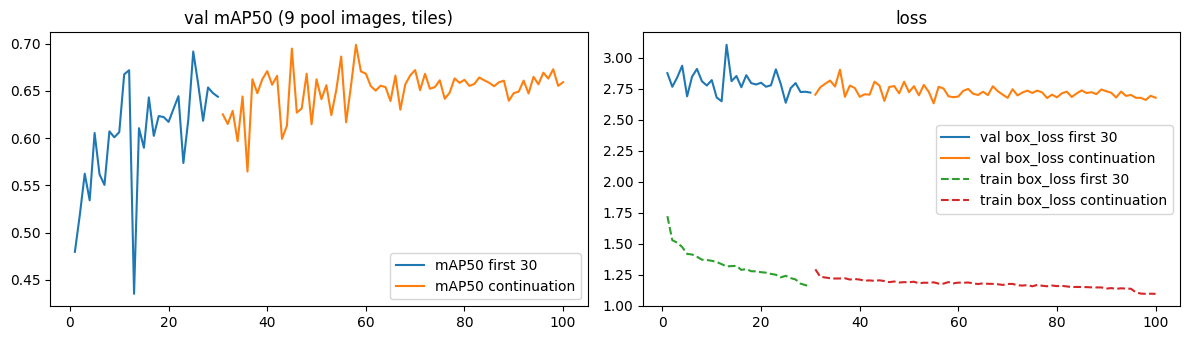


Done. Weights: /content/drive/MyDrive/yolo_runs/student_conf0.20_cont/weights/best.pt | /content/drive/MyDrive/yolo_runs/student_conf0.20_cont/weights/best_map50.pt | /content/drive/MyDrive/yolo_runs/student_conf0.20_cont/weights/last.pt 
The 3 held-back images have not been touched.


In [ ]:
# ===== STUDENT CONTINUATION (self-contained, works after a disconnect): rebuild the same tiles, train 70 more epochs from the finished student =====
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
from google.colab import drive
drive.mount('/content/drive')

import os, re, io, math, struct, zipfile, shutil, random, yaml
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------------- settings (identical to the first student run, so the tiles are identical) ----------------
LABEL_SET   = "labels_conf0.20"
DATASET_ZIP = "/content/drive/MyDrive/yolo_labelled_dataset.zip"
META_ZIP    = "/content/drive/MyDrive/dataset_parts/dataset_small_meta.zip"
PROJECT     = "/content/drive/MyDrive/yolo_runs"
NAME_BASE   = f"student_{LABEL_SET.replace('labels_', '')}"          # the finished 30-epoch run
NAME        = NAME_BASE + "_cont"                                      # the new run
START       = f"{PROJECT}/{NAME_BASE}/weights/last.pt"                 # weights to continue from (use .../best.pt to start from epoch 25 instead)
TILE, MAX_TILES, BATCH = 1024, 4000, 12
EPOCHS_MORE = 70
EXCLUDE_NOISY, KEEP_EMPTY = True, 0.2
N_FINAL = 3
EXPECTED_FINAL = ["val_img27", "val_img72", "val_img9"]
ROOT, BASE_DIR, RUN_DIR = f"/content/student_{LABEL_SET}", f"{PROJECT}/{NAME_BASE}", f"{PROJECT}/{NAME}"
assert torch.cuda.is_available(), "Switch the runtime to a GPU."
assert os.path.exists(START), f"weights to continue from not found: {START}"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ---------------- the 12 manual images: 9 pool -> per-epoch val, 3 held-back -> untouched ----------------
mz = zipfile.ZipFile(META_ZIP); mn = mz.namelist()
stem_of = lambda n: os.path.splitext(os.path.basename(n))[0]
meta_imgs = {stem_of(n): n for n in mn if os.path.splitext(n)[1].lower() in IMG_EXT}
meta_lbls = {stem_of(n): n for n in mn if n.endswith(".txt")}
order = list(np.random.default_rng(0).permutation(sorted(meta_imgs)))                       # same recipe as CV-1
final_stems = sorted(order[:N_FINAL]); pool_stems = [s for s in order if s not in final_stems]
print("held-back images (not opened anywhere in this cell):", final_stems)
assert final_stems == sorted(EXPECTED_FINAL), "held-back images differ from the ones used before -> stop and tell me"

def parse_boxes(text):
    rows = []
    for line in text.strip().splitlines():
        p = line.split()
        if len(p) < 5: continue
        v = list(map(float, p[1:]))
        if len(v) == 4: cx, cy, w, h = v
        else:
            xs, ys = v[0::2], v[1::2]; cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
        rows.append((cx, cy, w, h))
    return rows

def positions(L, grid):          # grid=True: exact non-overlapping grid (val); False: fewest tiles that cover the image (train)
    if L <= TILE: return [0]
    if grid: return list(range(0, L, TILE))
    return sorted(set(np.linspace(0, L - TILE, math.ceil(L / TILE)).round().astype(int).tolist()))

def tile_boxes(rows, W, H, x0, y0, min_vis=0.5):
    out = []
    for cx, cy, w, h in rows:
        x1, x2, y1, y2 = (cx-w/2)*W, (cx+w/2)*W, (cy-h/2)*H, (cy+h/2)*H
        ix1, ix2, iy1, iy2 = max(x1, x0), min(x2, x0+TILE), max(y1, y0), min(y2, y0+TILE)
        if ix2 <= ix1 or iy2 <= iy1 or (ix2-ix1)*(iy2-iy1) < min_vis*(x2-x1)*(y2-y1): continue      # keep boxes >= 50% visible
        out.append((((ix1+ix2)/2-x0)/TILE, ((iy1+iy2)/2-y0)/TILE, (ix2-ix1)/TILE, (iy2-iy1)/TILE))
    return out

def crop(img, x0, y0):
    c = img[y0:y0+TILE, x0:x0+TILE]; ph, pw = TILE - c.shape[0], TILE - c.shape[1]
    return cv2.copyMakeBorder(c, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=0) if (ph or pw) else c

def save_tile(split, name, img, boxes):
    for d in ("images", "labels"): os.makedirs(f"{ROOT}/{split}/{d}", exist_ok=True)
    cv2.imwrite(f"{ROOT}/{split}/images/{name}.png", img, [cv2.IMWRITE_PNG_COMPRESSION, 1])
    open(f"{ROOT}/{split}/labels/{name}.txt", "w").write("".join(f"0 {a:.6f} {b:.6f} {c:.6f} {d:.6f}\n" for a, b, c, d in boxes))

def img_size(zf, info):                                           # PNG header holds the size: no need to read the whole image
    with zf.open(info) as f: head = f.read(32)
    if head[:8] == b"\x89PNG\r\n\x1a\n": return struct.unpack(">II", head[16:24])
    from PIL import Image
    return Image.open(io.BytesIO(zf.read(info))).size

# ---------------- rebuild the tiled dataset (same seed + settings -> the same tiles as the first run) ----------------
def build():
    shutil.rmtree(ROOT, ignore_errors=True); rng = random.Random(0)
    z = zipfile.ZipFile(DATASET_ZIP); nset = set(z.namelist()); pre = "yolo_labelled_dataset/"
    infos = [i for i in z.infolist() if i.filename.startswith(pre + "images/train/") and not i.is_dir()]
    cand, n_excl, n_nolbl = [], 0, 0
    for k, info in enumerate(infos):                              # phase 1: list every candidate tile (headers + label text only)
        name = os.path.basename(info.filename); st = os.path.splitext(name)[0]
        if EXCLUDE_NOISY and re.match(r"^(p\d\d_)?noisy_", name): n_excl += 1; continue
        lbl = f"{pre}{LABEL_SET}/train/{st}.txt"
        if lbl not in nset: n_nolbl += 1; continue
        rows = parse_boxes(z.read(lbl).decode()); W, H = img_size(z, info)
        for y0 in positions(H, False):
            for x0 in positions(W, False):
                b = tile_boxes(rows, W, H, x0, y0)
                if b or rng.random() < KEEP_EMPTY: cand.append((k, x0, y0, b))
    if len(cand) > MAX_TILES: cand = rng.sample(cand, MAX_TILES)
    cand.sort(key=lambda t: t[0]); by_img = {}
    for k, x0, y0, b in cand: by_img.setdefault(k, []).append((x0, y0, b))
    for n_done, (k, tiles) in enumerate(by_img.items()):          # phase 2: decode each needed image once, cut its tiles
        img = cv2.imdecode(np.frombuffer(z.read(infos[k]), np.uint8), cv2.IMREAD_COLOR)
        st = re.sub(r"[^A-Za-z0-9._-]", "_", os.path.splitext(os.path.basename(infos[k].filename))[0])
        for x0, y0, b in tiles: save_tile("train", f"{k:05d}_{st}_x{x0}_y{y0}", crop(img, x0, y0), b)
        if n_done % 500 == 0: print(f"   cutting tiles: {n_done}/{len(by_img)} images")
    nb = [len(b) for _, _, _, b in cand]
    print(f"train: {len(infos)} images in zip | excluded noisy: {n_excl} | no label file: {n_nolbl} | tiles: {len(cand)} "
          f"| boxes/tile mean {np.mean(nb):.1f} | empty tiles {np.mean(np.array(nb) == 0):.0%}")
    nv, ni = 0, 0                                                 # val: the 9 pool images only, as non-overlapping native tiles
    for st in pool_stems:
        img = cv2.imdecode(np.frombuffer(mz.read(meta_imgs[st]), np.uint8), cv2.IMREAD_COLOR); H, W = img.shape[:2]
        rows = parse_boxes(mz.read(meta_lbls[st]).decode())
        for y0 in positions(H, True):
            for x0 in positions(W, True):
                b = tile_boxes(rows, W, H, x0, y0)
                if b: save_tile("val", f"{st}_x{x0}_y{y0}", crop(img, x0, y0), b); nv += 1; ni += len(b)
    print(f"val: {len(pool_stems)} pool images -> {nv} tiles, {ni} manual boxes   (the first run reported 37 tiles / 451 boxes)")
    yaml.safe_dump(dict(path=ROOT, train="train/images", val="val/images", names={0: "aggregate"}), open(f"{ROOT}/data.yaml", "w"))

if not os.path.exists(f"{ROOT}/data.yaml"): build()
else: print("tiled dataset already on disk, reusing it")

# ---------------- continuation training (Drive-saved, halt anytime, resumable, skips itself once finished) ----------------
AUG = dict(hsv_h=0.02, hsv_s=0.9, hsv_v=0.6, degrees=0, translate=0.15, scale=0.4, shear=0, perspective=0,
           flipud=0.5, fliplr=0.5, mosaic=1.0, mixup=0.1)
ARGS = dict(data=f"{ROOT}/data.yaml", imgsz=TILE, epochs=EPOCHS_MORE, batch=BATCH, patience=0, seed=0, project=PROJECT, name=NAME,
            exist_ok=True, workers=2, val=True, save_period=5, close_mosaic=5,
            warmup_epochs=0, optimizer="AdamW", lr0=0.0005, **AUG)     # lower lr, no warm-up: this continues, it doesn't restart
best, DONE = {"map50": -1.0}, f"{RUN_DIR}/DONE"
def keep_best_map50(trainer):                                         # end of every epoch: keep the best val-mAP50 checkpoint
    if trainer.epoch >= trainer.epochs: return                        # skip the extra call Ultralytics makes after training ends
    m = trainer.metrics.get("metrics/mAP50(B)")
    if m is not None and m > best["map50"]:
        best["map50"] = float(m); shutil.copy(trainer.last, trainer.wdir / "best_map50.pt")
        print(f"   >> new best val mAP50 {m:.3f} at epoch {trainer.epoch + 1} -> best_map50.pt")

def load_results(d=RUN_DIR):
    r = pd.read_csv(f"{d}/results.csv"); r.columns = [c.strip() for c in r.columns]; return r

def run():
    if os.path.exists(DONE): print("continuation already finished -> skipping training"); return
    resume = os.path.exists(f"{RUN_DIR}/weights/last.pt")
    if resume:
        print("found an unfinished continuation -> resuming it"); model = YOLO(f"{RUN_DIR}/weights/last.pt")
        best["map50"] = float(load_results()["metrics/mAP50(B)"].max())
    else: model = YOLO(START)
    model.add_callback("on_fit_epoch_end", keep_best_map50)
    try:
        model.train(resume=True) if resume else model.train(**ARGS)
        os.makedirs(RUN_DIR, exist_ok=True); open(DONE, "w").write("ok")
    except KeyboardInterrupt: print("\nHalted by you. last.pt is saved; rerun this cell to continue.")
    except Exception as e:
        if "nothing to resume" in str(e) or "is finished" in str(e): open(DONE, "w").write("ok"); print("the continuation had already finished.")
        else: raise

def report():
    d = load_results(); cols = [c for c in ["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)", "train/box_loss", "val/box_loss"] if c in d.columns]
    print(f"top epochs of the continuation by mAP50 on the 9 pool images (tiles):"); print(d[cols].sort_values("metrics/mAP50(B)", ascending=False).head(8).round(3).to_string(index=False))
    try:
        b = load_results(BASE_DIR); print(f"first run: best mAP50 {b['metrics/mAP50(B)'].max():.3f} (epoch {int(b.loc[b['metrics/mAP50(B)'].idxmax(), 'epoch'])}); continuation: best {d['metrics/mAP50(B)'].max():.3f}")
        d = d.assign(epoch=d["epoch"] + len(b)); fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
        for dd, lab in ((b, "first 30"), (d, "continuation")):
            ax[0].plot(dd["epoch"], dd["metrics/mAP50(B)"], label=f"mAP50 {lab}"); ax[1].plot(dd["epoch"], dd["val/box_loss"], label=f"val box_loss {lab}")
        ax[1].plot(b["epoch"], b["train/box_loss"], "--", label="train box_loss first 30"); ax[1].plot(d["epoch"], d["train/box_loss"], "--", label="train box_loss continuation")
        ax[0].set_title("val mAP50 (9 pool images, tiles)"); ax[1].set_title("loss"); ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()
    except Exception as e: print("could not plot the first run for comparison:", e)

run()
report()
print("\nDone. Weights:", f"{RUN_DIR}/weights/best.pt", "|", f"{RUN_DIR}/weights/best_map50.pt", "|", f"{RUN_DIR}/weights/last.pt", "\nThe 3 held-back images have not been touched.")

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
held-back images (not opened anywhere in this cell): [np.str_('val_img27'), np.str_('val_img72'), np.str_('val_img9')]

[labels_conf0.05] STEP 1: 5000 images | noisy: 653 | clean images indexed for partner lookup: 4347
[labels_conf0.05] STEP 2: alignment of noisy/partner pairs: n=57, correlation min 0.26 / median 0.97
[labels_conf0.05] STEPS 3-4 RESULT
image_type                                      clean  noisy
status                                                      
dropped: fewer than 1 box(es)                      43      1
kept: labels copied from clean partner              0     55
kept: own labels                                 4304      0
noisy dropped: no clea

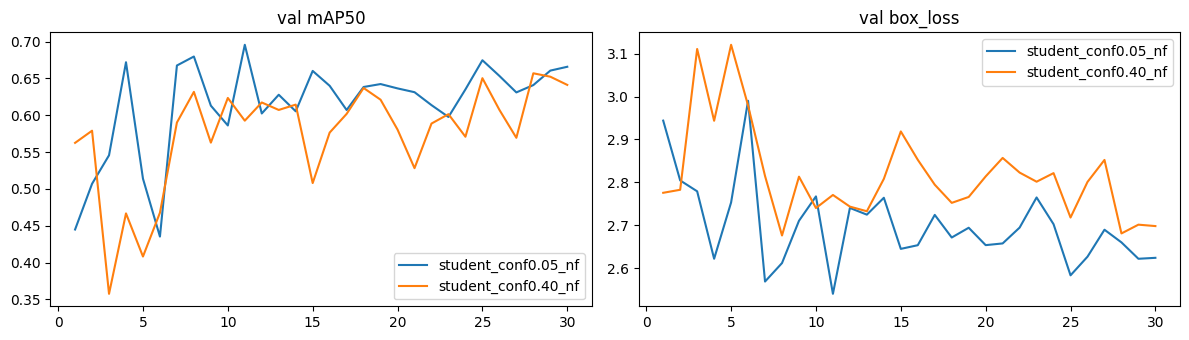


Held-out check: add these to MODELS in the held-out cell -> ['/content/drive/MyDrive/yolo_runs/student_conf0.05_nf/weights/best.pt', '/content/drive/MyDrive/yolo_runs/student_conf0.40_nf/weights/best.pt'] 
The 3 held-back images have not been touched.


In [ ]:
# ===== STUDENT-NF (one self-contained cell): copy clean labels to noisy images -> drop under-labelled images -> tile -> train each label set =====
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
from google.colab import drive
drive.mount('/content/drive')

import os, re, io, math, struct, zipfile, shutil, random, yaml
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------------- settings ----------------
LABEL_SETS  = ["labels_conf0.05", "labels_conf0.40"]     # trained one after the other; add "labels_conf0.20" for a like-for-like comparison
DATASET_ZIP = "/content/drive/MyDrive/yolo_labelled_dataset.zip"
META_ZIP    = "/content/drive/MyDrive/dataset_parts/dataset_small_meta.zip"
PROJECT     = "/content/drive/MyDrive/yolo_runs"
MIN_BOXES   = 1          # drop an image if its (final) label file has fewer boxes than this
MIN_CORR    = 0.5        # a noisy image only receives its clean partner's labels if the two images correlate at least this much (same geometry)
TILE, MAX_TILES, BATCH, EPOCHS, KEEP_EMPTY = 1024, 4000, 12, 30, 0.2
N_FINAL, EXPECTED_FINAL = 3, ["val_img27", "val_img72", "val_img9"]
assert torch.cuda.is_available(), "Switch the runtime to a GPU."
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ---------------- the 12 manual images: 9 pool -> per-epoch val, 3 held-back -> untouched ----------------
mz = zipfile.ZipFile(META_ZIP); mn = mz.namelist()
stem_of = lambda n: os.path.splitext(os.path.basename(n))[0]
meta_imgs = {stem_of(n): n for n in mn if os.path.splitext(n)[1].lower() in IMG_EXT}
meta_lbls = {stem_of(n): n for n in mn if n.endswith(".txt")}
order = list(np.random.default_rng(0).permutation(sorted(meta_imgs)))                       # same recipe as CV-1
final_stems = sorted(order[:N_FINAL]); pool_stems = [s for s in order if s not in final_stems]
print("held-back images (not opened anywhere in this cell):", final_stems)
assert final_stems == sorted(EXPECTED_FINAL), "held-back images differ from the ones used before -> stop and tell me"

def parse_boxes(text):
    rows = []
    for line in text.strip().splitlines():
        p = line.split()
        if len(p) < 5: continue
        v = list(map(float, p[1:]))
        if len(v) == 4: cx, cy, w, h = v
        else:
            xs, ys = v[0::2], v[1::2]; cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
        rows.append((cx, cy, w, h))
    return rows

def positions(L, grid):          # grid=True: exact non-overlapping grid (val); False: fewest tiles that cover the image (train)
    if L <= TILE: return [0]
    if grid: return list(range(0, L, TILE))
    return sorted(set(np.linspace(0, L - TILE, math.ceil(L / TILE)).round().astype(int).tolist()))

def tile_boxes(rows, W, H, x0, y0, min_vis=0.5):
    out = []
    for cx, cy, w, h in rows:
        x1, x2, y1, y2 = (cx-w/2)*W, (cx+w/2)*W, (cy-h/2)*H, (cy+h/2)*H
        ix1, ix2, iy1, iy2 = max(x1, x0), min(x2, x0+TILE), max(y1, y0), min(y2, y0+TILE)
        if ix2 <= ix1 or iy2 <= iy1 or (ix2-ix1)*(iy2-iy1) < min_vis*(x2-x1)*(y2-y1): continue      # keep boxes >= 50% visible
        out.append((((ix1+ix2)/2-x0)/TILE, ((iy1+iy2)/2-y0)/TILE, (ix2-ix1)/TILE, (iy2-iy1)/TILE))
    return out

def crop(img, x0, y0):
    c = img[y0:y0+TILE, x0:x0+TILE]; ph, pw = TILE - c.shape[0], TILE - c.shape[1]
    return cv2.copyMakeBorder(c, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=0) if (ph or pw) else c

def img_size(zf, info):                                           # PNG header holds the size: no need to read the whole image
    with zf.open(info) as f: head = f.read(32)
    if head[:8] == b"\x89PNG\r\n\x1a\n": return struct.unpack(">II", head[16:24])
    from PIL import Image
    return Image.open(io.BytesIO(zf.read(info))).size

def parse_name(stem):            # 'noisy_g1_img6670' -> (True, ('g1', 6670)); 'orig_0°img72' -> (False, ('orig_0°', 72))
    s = re.sub(r"^p\d\d_", "", stem); noisy = s.startswith("noisy_")
    if noisy: s = s[len("noisy_"):]
    m = re.match(r"^(.*?)_?img(\d+)$", s)
    return noisy, ((m.group(1), int(m.group(2))) if m else (s, -1))

def correlation(z, ia, ib):      # how alike are two images (brightest channel, shrunk): ~1 = same picture, ~0 = unrelated, None = different size
    a = cv2.imdecode(np.frombuffer(z.read(ia), np.uint8), cv2.IMREAD_COLOR); b = cv2.imdecode(np.frombuffer(z.read(ib), np.uint8), cv2.IMREAD_COLOR)
    if a is None or b is None or a.shape != b.shape: return None
    f = lambda x: cv2.resize(x.max(axis=2), (128, max(int(128 * x.shape[0] / x.shape[1]), 1)), interpolation=cv2.INTER_AREA).astype(np.float32)
    a, b = f(a), f(b)
    if a.std() < 1e-6 or b.std() < 1e-6: return 0.0
    return float(((a - a.mean()) / a.std() * (b - b.mean()) / b.std()).mean())

# ---------------- STEPS 1-4: decide the labels of every image ----------------
def prepare(label_set):
    z = zipfile.ZipFile(DATASET_ZIP); nset = set(z.namelist()); pre = "yolo_labelled_dataset/"
    infos = [i for i in z.infolist() if i.filename.startswith(pre + "images/train/") and not i.is_dir()]
    stems = [os.path.splitext(os.path.basename(i.filename))[0] for i in infos]
    own = [parse_boxes(z.read(f"{pre}{label_set}/train/{st}.txt").decode()) if f"{pre}{label_set}/train/{st}.txt" in nset else None for st in stems]
    parsed = [parse_name(s) for s in stems]
    clean_idx = {}
    for k, (noisy, key) in enumerate(parsed):
        if not noisy and key[1] >= 0: clean_idx.setdefault(key, k)
    rows, status, corrs = [None] * len(infos), {}, []
    print(f"\n[{label_set}] STEP 1: {len(infos)} images | noisy: {sum(n for n, _ in parsed)} | clean images indexed for partner lookup: {len(clean_idx)}")
    for k, (noisy, key) in enumerate(parsed):
        if own[k] is None and not noisy: status[k] = "no label file"; continue
        if not noisy: rows[k] = own[k]; status[k] = "kept: own labels"; continue
        j = clean_idx.get(key)
        if j is None or own[j] is None: status[k] = "noisy dropped: no clean partner in the dataset"; continue
        c = correlation(z, infos[k], infos[j])                                      # STEP 2: is the partner really the same picture?
        if c is not None: corrs.append(c)
        if c is None or c < MIN_CORR: status[k] = "noisy dropped: partner not pixel-aligned"; continue
        rows[k] = own[j]; status[k] = "kept: labels copied from clean partner"       # STEP 3: copy the clean partner's labels
    if corrs: print(f"[{label_set}] STEP 2: alignment of noisy/partner pairs: n={len(corrs)}, correlation min {min(corrs):.2f} / median {np.median(corrs):.2f}")
    for k in range(len(infos)):                                                      # STEP 4: drop images with too few boxes
        if rows[k] is not None and len(rows[k]) < MIN_BOXES: rows[k] = None; status[k] = f"dropped: fewer than {MIN_BOXES} box(es)"
    df = pd.DataFrame(dict(status=[status[k] for k in range(len(infos))], image_type=["noisy" if p[0] else "clean" for p in parsed]))
    print(f"[{label_set}] STEPS 3-4 RESULT"); print(pd.crosstab(df.status, df.image_type).to_string())
    kept = [k for k in range(len(infos)) if rows[k] is not None]
    print(f"[{label_set}] images kept for training: {len(kept)} of {len(infos)} | boxes per kept image: mean {np.mean([len(rows[k]) for k in kept]):.1f}")
    return z, infos, stems, rows

# ---------------- tiles ----------------
def build(label_set, root):
    shutil.rmtree(root, ignore_errors=True); rng = random.Random(0)
    z, infos, stems, rows = prepare(label_set)
    def save_tile(split, name, img, boxes):
        for d in ("images", "labels"): os.makedirs(f"{root}/{split}/{d}", exist_ok=True)
        cv2.imwrite(f"{root}/{split}/images/{name}.png", img, [cv2.IMWRITE_PNG_COMPRESSION, 1])
        open(f"{root}/{split}/labels/{name}.txt", "w").write("".join(f"0 {a:.6f} {b:.6f} {c:.6f} {d:.6f}\n" for a, b, c, d in boxes))
    cand = []
    for k, info in enumerate(infos):
        if rows[k] is None: continue
        W, H = img_size(z, info)
        for y0 in positions(H, False):
            for x0 in positions(W, False):
                b = tile_boxes(rows[k], W, H, x0, y0)
                if b or rng.random() < KEEP_EMPTY: cand.append((k, x0, y0, b))
    if len(cand) > MAX_TILES: cand = rng.sample(cand, MAX_TILES)
    cand.sort(key=lambda t: t[0]); by_img = {}
    for k, x0, y0, b in cand: by_img.setdefault(k, []).append((x0, y0, b))
    for n_done, (k, tiles) in enumerate(by_img.items()):
        img = cv2.imdecode(np.frombuffer(z.read(infos[k]), np.uint8), cv2.IMREAD_COLOR)
        st = re.sub(r"[^A-Za-z0-9._-]", "_", stems[k])
        for x0, y0, b in tiles: save_tile("train", f"{k:05d}_{st}_x{x0}_y{y0}", crop(img, x0, y0), b)
        if n_done % 500 == 0: print(f"   cutting tiles: {n_done}/{len(by_img)} images")
    nb = np.array([len(b) for _, _, _, b in cand])
    print(f"[{label_set}] STEP 5: train tiles {len(cand)} | boxes/tile mean {nb.mean():.1f} | empty tiles {np.mean(nb == 0):.0%}")
    nv, ni = 0, 0                                                 # val: the 9 pool images only, as non-overlapping native tiles
    for st in pool_stems:
        img = cv2.imdecode(np.frombuffer(mz.read(meta_imgs[st]), np.uint8), cv2.IMREAD_COLOR); H, W = img.shape[:2]
        mrows = parse_boxes(mz.read(meta_lbls[st]).decode())
        for y0 in positions(H, True):
            for x0 in positions(W, True):
                b = tile_boxes(mrows, W, H, x0, y0)
                if b: save_tile("val", f"{st}_x{x0}_y{y0}", crop(img, x0, y0), b); nv += 1; ni += len(b)
    print(f"[{label_set}] val: {len(pool_stems)} pool images -> {nv} tiles, {ni} manual boxes (earlier runs: 37 tiles / 451 boxes)")
    yaml.safe_dump(dict(path=root, train="train/images", val="val/images", names={0: "aggregate"}), open(f"{root}/data.yaml", "w"))

# ---------------- training: Drive-saved, resumable, skips finished runs ----------------
AUG = dict(hsv_h=0.02, hsv_s=0.9, hsv_v=0.6, degrees=0, translate=0.15, scale=0.4, shear=0, perspective=0, flipud=0.5, fliplr=0.5, mosaic=1.0, mixup=0.1)
best = {"map50": -1.0}
def keep_best_map50(trainer):
    if trainer.epoch >= trainer.epochs: return                        # skip the extra call Ultralytics makes after training ends
    m = trainer.metrics.get("metrics/mAP50(B)")
    if m is not None and m > best["map50"]:
        best["map50"] = float(m); shutil.copy(trainer.last, trainer.wdir / "best_map50.pt")
        print(f"   >> new best val mAP50 {m:.3f} at epoch {trainer.epoch + 1} -> best_map50.pt")

def load_results(d):
    r = pd.read_csv(f"{d}/results.csv"); r.columns = [c.strip() for c in r.columns]; return r

def train_set(label_set):
    name = f"student_{label_set.replace('labels_', '')}_nf"; run_dir = f"{PROJECT}/{name}"; root = f"/content/student_nf_{label_set}"
    if os.path.exists(f"{run_dir}/DONE"): print(f"\n[{label_set}] already finished -> skipped"); return name
    resume = os.path.exists(f"{run_dir}/weights/last.pt")
    if not os.path.exists(f"{root}/data.yaml"): build(label_set, root)
    else: print(f"[{label_set}] tiled dataset already on disk, reusing it")
    best["map50"] = float(load_results(run_dir)["metrics/mAP50(B)"].max()) if resume else -1.0
    model = YOLO(f"{run_dir}/weights/last.pt") if resume else YOLO("yolo11n.pt")
    model.add_callback("on_fit_epoch_end", keep_best_map50)
    args = dict(data=f"{root}/data.yaml", imgsz=TILE, epochs=EPOCHS, batch=BATCH, patience=0, seed=0, project=PROJECT, name=name,
                exist_ok=True, workers=2, val=True, save_period=5, close_mosaic=3, **AUG)
    print(f"[{label_set}] training {name}: {EPOCHS} epochs" + (" (resuming)" if resume else ""))
    try:
        model.train(resume=True) if resume else model.train(**args)
        os.makedirs(run_dir, exist_ok=True); open(f"{run_dir}/DONE", "w").write("ok"); shutil.rmtree(root, ignore_errors=True)   # free disk
    except KeyboardInterrupt: print("\nHalted by you. Rerun this cell to continue; finished sets are skipped, an unfinished one resumes."); raise
    except Exception as e:
        if "nothing to resume" in str(e) or "is finished" in str(e): open(f"{run_dir}/DONE", "w").write("ok"); print("this run had already finished.")
        else: raise
    return name

names = []
for ls in LABEL_SETS: names.append(train_set(ls))

print("\n===== SUMMARY: best epoch per run on the 9 pool images (tiles; the teacher saw these, so read it as relative, not absolute) =====")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for nm in names:
    d = load_results(f"{PROJECT}/{nm}"); i = d["metrics/mAP50(B)"].idxmax()
    print(f"{nm}: best mAP50 {d.loc[i, 'metrics/mAP50(B)']:.3f} at epoch {int(d.loc[i, 'epoch'])} | P {d.loc[i, 'metrics/precision(B)']:.3f} R {d.loc[i, 'metrics/recall(B)']:.3f} | last-5-epoch mean mAP50 {d['metrics/mAP50(B)'].tail(5).mean():.3f}")
    ax[0].plot(d["epoch"], d["metrics/mAP50(B)"], label=nm); ax[1].plot(d["epoch"], d["val/box_loss"], label=nm)
ax[0].set_title("val mAP50"); ax[1].set_title("val box_loss"); ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()
print("\nHeld-out check: add these to MODELS in the held-out cell ->", [f'{PROJECT}/{n}/weights/best.pt' for n in names], "\nThe 3 held-back images have not been touched.")

In [ ]:
# ===== RESULTS: one cell that records everything (split check + test set, all model metrics, teacher-vs-student, dataset composition) =====
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
from google.colab import drive
drive.mount('/content/drive')

import os, re, io, math, zipfile, shutil, yaml, random, collections
import numpy as np, pandas as pd, cv2
from ultralytics import YOLO
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
try:
    import torch; print("device:", "GPU" if torch.cuda.is_available() else "CPU (works, but slower)")
except Exception: pass
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 300)

# ---------------- settings ----------------
DRIVE       = "/content/drive/MyDrive"
PROJECT     = f"{DRIVE}/yolo_runs"
META_ZIP    = f"{DRIVE}/dataset_parts/dataset_small_meta.zip"      # the 12 manually annotated val images
ORIG_ZIP    = f"{DRIVE}/orig_imgs.zip"                              # the 116 original images
DATASET_ZIP = f"{DRIVE}/yolo_labelled_dataset.zip"                  # the pseudo-labelled 5k
OUT         = f"{DRIVE}/paper_results"                              # every table below is also saved here as CSV
EVALROOT    = "/content/evalsets"
CONFS       = (0.05, 0.20, 0.40)
N_FINAL, EXPECTED_FINAL = 3, ["val_img27", "val_img72", "val_img9"]
NMS_IOU, MAX_DET = 0.6, 1000
RUN_ULTRALYTICS_VAL, RUN_COMPOSITION = True, True
FULL_PER_VARIANT, FULL_NOISY, STRIDE = 13284, 4098, 11              # from your description of the full 57,234-image set
os.makedirs(OUT, exist_ok=True)

FOLDS_W   = {k: f"{PROJECT}/cv_fold{k}/weights/last.pt" for k in range(3)}
TEACHER_W = f"{PROJECT}/teacher/weights/last.pt"
STUDENT_W = {"S05": f"{PROJECT}/student_conf0.05_nf/weights/best.pt",     # student trained on teacher labels with conf >= 0.05
             "S20": f"{PROJECT}/student_conf0.20/weights/best.pt",        # ... conf >= 0.20  (first run: noisy images excluded)
             "S40": f"{PROJECT}/student_conf0.40_nf/weights/best.pt",     # ... conf >= 0.40
             "S20c": f"{PROJECT}/student_conf0.20_cont/weights/best.pt"}  # ... conf >= 0.20 continued (only if it exists)
for k, w in STUDENT_W.items():
    if not os.path.exists(w): print(f"note: student {k} weights not found -> skipped ({w})")
STUDENT_W = {k: w for k, w in STUDENT_W.items() if os.path.exists(w)}

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
stem_of = lambda n: os.path.splitext(os.path.basename(n))[0]
jnum = lambda s: int(re.search(r"(\d+)(?:\.\w+)?$", s).group(1))          # works for "val_img27" and "test_img10.png"
def save(name, df): df.to_csv(f"{OUT}/{name}.csv", index=False)
def banner(t): print("\n" + "=" * 110 + "\n" + t + "\n" + "=" * 110)

def parse_boxes(text):
    rows = []
    for line in text.strip().splitlines():
        p = line.split()
        if len(p) < 5: continue
        v = list(map(float, p[1:]))
        if len(v) == 4: cx, cy, w, h = v
        else:
            xs, ys = v[0::2], v[1::2]; cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
        rows.append((cx, cy, w, h))
    return rows

# =====================================================================================================
banner("1. THE 12 MANUALLY ANNOTATED VAL IMAGES  (9 pool images + 3 held-out images)")
mz = zipfile.ZipFile(META_ZIP); mn = mz.namelist()
meta_imgs = {stem_of(n): n for n in mn if os.path.splitext(n)[1].lower() in IMG_EXT}
meta_lbls = {stem_of(n): n for n in mn if n.endswith(".txt")}
imgs, gts = {}, {}
for s in sorted(meta_imgs):
    a = cv2.imdecode(np.frombuffer(mz.read(meta_imgs[s]), np.uint8), cv2.IMREAD_COLOR); H, W = a.shape[:2]
    rows = parse_boxes(mz.read(meta_lbls[s]).decode()) if s in meta_lbls else []
    imgs[s] = a; gts[s] = np.array([[(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H] for cx, cy, w, h in rows]).reshape(-1, 4)
order = list(np.random.default_rng(0).permutation(sorted(imgs)))                    # same recipe as every earlier cell
final_stems = sorted(order[:N_FINAL]); pool_stems = [s for s in order if s not in final_stems]
assert final_stems == sorted(EXPECTED_FINAL), "held-out images differ from the earlier ones -> stop and tell me"
K = max(len(pool_stems) // 3, 2); folds = [pool_stems[i::K] for i in range(K)]
fold_of = {s: k for k, f in enumerate(folds) for s in f}
IMGSZ = int(math.ceil(max(max(a.shape[:2]) for a in imgs.values()) / 32) * 32)
tab = pd.DataFrame([dict(image=s, role="held-out" if s in final_stems else "pool", cv_fold=fold_of.get(s, "-"),
                         size=f"{imgs[s].shape[1]}x{imgs[s].shape[0]}", manual_boxes=len(gts[s])) for s in sorted(imgs, key=jnum)])
print(tab.to_string(index=False)); save("01_val_images_manual_boxes", tab)
print(f"\nTOTAL manually drawn boxes in the 12 val images: {int(tab.manual_boxes.sum())}"
      f" | 9 pool images: {int(tab[tab.role == 'pool'].manual_boxes.sum())} | 3 held-out images: {int(tab[tab.role == 'held-out'].manual_boxes.sum())}")
allbox = np.concatenate([g for g in gts.values() if len(g)])
BOX_PX = float(np.median(((allbox[:, 2] - allbox[:, 0]) + (allbox[:, 3] - allbox[:, 1])) / 2))
print(f"median manual box size: {np.median(allbox[:, 2] - allbox[:, 0]):.0f} x {np.median(allbox[:, 3] - allbox[:, 1]):.0f} px | inference size for whole images: {IMGSZ}")
for k, f in enumerate(folds): print(f"cross-fold {k}: held-out {sorted(f, key=jnum)} | trained on the other {len(pool_stems) - len(f)} pool images")

# =====================================================================================================
banner("2. TRAIN / VAL / TEST SPLIT OF THE 116 ORIGINALS (MATLAB rule) AND THE 12-IMAGE TEST SET")
print("rule (j = 1-based position of the file in MATLAB's imageDatastore list):\n"
      "   val   : mod(j, 9) == 0                -> j = 9, 18, ..., 108      (every 9th image)\n"
      "   test  : mod(j, 9) == 1 and j > 1      -> j = 10, 19, ..., 109     (the image right AFTER each val image)\n"
      "   train : everything else (incl. image 1)")
def thumb(a):
    g = a.max(axis=2) if a.ndim == 3 else a
    return cv2.resize(g, (128, max(int(round(128 * g.shape[0] / g.shape[1])), 1)), interpolation=cv2.INTER_AREA).astype(np.float32)
def corr(a, b):
    if a.shape != b.shape: return -1.0
    sa, sb = a.std(), b.std()
    return 0.0 if sa < 1e-6 or sb < 1e-6 else float(((a - a.mean()) / sa * (b - b.mean()) / sb).mean())
natkey = lambda n: [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", n)]
SPLIT_OK, TEST_DIR = False, f"{OUT}/test_set_12"
if not os.path.exists(ORIG_ZIP): print(f"\n{ORIG_ZIP} not found -> split check and test set skipped")
else:
    oz = zipfile.ZipFile(ORIG_ZIP)
    omem = [i.filename for i in oz.infolist() if not i.is_dir() and os.path.splitext(i.filename)[1].lower() in IMG_EXT
            and "__MACOSX" not in i.filename and not os.path.basename(i.filename).startswith(".")]
    n = len(omem); obase = [os.path.basename(m) for m in omem]
    print(f"\n{n} original images found in the zip" + ("" if n == 116 else "   <-- expected 116, check the zip"))
    ot = []
    for m in omem:
        a = cv2.imdecode(np.frombuffer(oz.read(m), np.uint8), cv2.IMREAD_COLOR); ot.append(thumb(a) if a is not None else np.zeros((1, 1), np.float32))
    vs = sorted(imgs, key=jnum); vt = {s: thumb(imgs[s]) for s in vs}
    C = np.array([[corr(vt[s], ot[o]) for o in range(n)] for s in vs]); best_o, best_c = C.argmax(1), C.max(1)
    ORDERINGS = {"ASCII by file name": sorted(range(n), key=lambda i: obase[i]),
                 "ASCII, case-insensitive": sorted(range(n), key=lambda i: obase[i].lower()),
                 "natural (numbers sorted numerically)": sorted(range(n), key=lambda i: natkey(obase[i])),
                 "order inside the zip": list(range(n))}
    score = {nm: sum(1 for vi, s in enumerate(vs) if jnum(s) <= n and perm[jnum(s) - 1] == best_o[vi] and best_c[vi] > 0.98) for nm, perm in ORDERINGS.items()}
    print("which file ordering reproduces your 12 val images (val_img{j} must be the j-th file; content compared pixel-wise):")
    for nm, sc in score.items(): print(f"   {nm:40s} {sc}/{len(vs)} val images match")
    best_name = max(score, key=score.get)
    if score[best_name] == len(vs):
        perm = ORDERINGS[best_name]; print(f"-> ordering confirmed: {best_name}")
        role = {j: "val" if j % 9 == 0 else ("test" if (j % 9 == 1 and j > 1) else "train") for j in range(1, n + 1)}
        cnt = collections.Counter(role.values())
        print(f"\nSplit complete.  Train: {cnt['train']} ({100*cnt['train']/n:.1f}%) | Val: {cnt['val']} ({100*cnt['val']/n:.1f}%) | Test: {cnt['test']} ({100*cnt['test']/n:.1f}%) | Total: {n}")
        man = pd.DataFrame([dict(j=j, role=role[j], saved_name=f"{role[j]}_img{j}.png", original_file=obase[perm[j-1]]) for j in range(1, n + 1)])
        save("02_split_manifest", man)
        adj = pd.DataFrame([dict(val_img=f"val_img{j}", original_file=obase[perm[j-1]], previous_file_in_order=f"{'(train) ' + obase[perm[j-2]]}",
                                 next_file_in_order=f"(test) {obase[perm[j]]}" if j < n else "-") for j in sorted(jnum(s) for s in vs)])
        print("\nval images and their neighbours in the file order (each test image is the file right after a val image):"); print(adj.to_string(index=False))
        os.makedirs(TEST_DIR, exist_ok=True)
        for j in [j for j in role if role[j] == "test"]:
            a = cv2.imdecode(np.frombuffer(oz.read(omem[perm[j-1]]), np.uint8), cv2.IMREAD_COLOR); cv2.imwrite(f"{TEST_DIR}/test_img{j}.png", a)
        print(f"\n12 test images written to {TEST_DIR}:", sorted(os.listdir(TEST_DIR), key=jnum)); SPLIT_OK = True
    else:
        print("\n-> NO ordering reproduces all 12 val images, so the test set was NOT generated (it would be the wrong files).")
        print("   best content match for each val image (use this to see how the files are ordered):")
        print(pd.DataFrame(dict(val_image=vs, matched_original=[obase[o] for o in best_o], correlation=best_c.round(3))).to_string(index=False))
        print("   first 12 file names in the zip:", obase[:12], "-> tell me how the files in your MATLAB folder were named/sorted")

# =====================================================================================================
# ---------------- inference + metrics (identical implementation for every model) ----------------
_MODELS, PRED = {}, {}
def get_model(w):
    if w not in _MODELS: _MODELS[w] = YOLO(w)
    return _MODELS[w]
def predict(w, key, img):                     # whole image at native scale; keeps everything >= 0.001
    if (w, key) not in PRED:
        r = get_model(w).predict(img, imgsz=int(math.ceil(max(img.shape[:2]) / 32) * 32), conf=0.001, iou=NMS_IOU, max_det=MAX_DET, verbose=False)[0]
        PRED[(w, key)] = np.hstack([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]])
    return PRED[(w, key)]
def preds_val(w): return {s: predict(w, s, imgs[s]) for s in imgs}

def iou_mat(a, b):
    if not len(a) or not len(b): return np.zeros((len(a), len(b)))
    iw = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    ih = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = iw * ih; ar = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)
def match_records(P, stems, thr):             # greedy one-to-one matching by confidence; returns (conf, is_tp) rows and #manual
    rec, n_gt = [], 0
    for s in stems:
        g, p = gts[s], P[s]; n_gt += len(g)
        if not len(p): continue
        p = p[np.argsort(-p[:, 4])]
        if not len(g): rec += [(c, 0) for c in p[:, 4]]; continue
        iou = iou_mat(p[:, :4], g); used = np.zeros(len(g), bool)
        for i in range(len(p)):
            cand = np.where(used, -1.0, iou[i]); j = int(cand.argmax())
            if cand[j] >= thr: used[j] = True; rec.append((p[i, 4], 1))
            else: rec.append((p[i, 4], 0))
    return np.array(rec).reshape(-1, 2), n_gt
def ap_of(rec, n_gt):
    if not len(rec) or n_gt == 0: return 0.0
    rec = rec[np.argsort(-rec[:, 0])]; tp = np.cumsum(rec[:, 1]); fp = np.cumsum(1 - rec[:, 1])
    R, Pc = tp / n_gt, tp / np.maximum(tp + fp, 1e-9)
    mr = np.concatenate([[0], R, [1]]); mp = np.concatenate([[0], Pc, [0]]); mp = np.maximum.accumulate(mp[::-1])[::-1]
    i = np.where(mr[1:] != mr[:-1])[0]; return float(np.sum((mr[i + 1] - mr[i]) * mp[i + 1]))
def metrics_row(P, stems, conf):              # everything computed only from detections with confidence >= conf
    sub = {s: P[s][P[s][:, 4] >= conf] for s in stems}; d = {}
    for thr, nm in ((0.25, "AP25"), (0.30, "AP30"), (0.50, "AP50"), (0.75, "AP75")): d[nm] = ap_of(*match_records(sub, stems, thr))
    d["mAP50-95"] = float(np.mean([ap_of(*match_records(sub, stems, t)) for t in np.arange(0.5, 0.951, 0.05)]))
    for thr, tag in ((0.30, "30"), (0.50, "50")):
        rec, n_gt = match_records(sub, stems, thr); tp = rec[:, 1].sum() if len(rec) else 0
        p, r = tp / max(len(rec), 1), tp / max(n_gt, 1); d[f"P{tag}"], d[f"R{tag}"], d[f"F1_{tag}"] = p, r, 2 * p * r / max(p + r, 1e-9)
    d["n_pred"], d["n_manual"] = sum(len(v) for v in sub.values()), sum(len(gts[s]) for s in stems); return d
def table(P, stems, label, set_label):
    return pd.DataFrame([dict(model=label, set=set_label, conf="all(.001)" if c == 0.001 else c, **metrics_row(P, stems, c)) for c in (0.001,) + CONFS])
def ultra(w, stems, tag):                     # Ultralytics' own val metrics (P/R at best-F1 confidence, mAP at IoU .5 and .5:.95)
    if not RUN_ULTRALYTICS_VAL: return {}
    try:
        root = f"{EVALROOT}/{tag}"; shutil.rmtree(root, ignore_errors=True)
        for d in ("images", "labels"): os.makedirs(f"{root}/{d}")
        for s in stems:
            open(f"{root}/images/{s}{os.path.splitext(meta_imgs[s])[1]}", "wb").write(mz.read(meta_imgs[s]))
            H, W = imgs[s].shape[:2]
            open(f"{root}/labels/{s}.txt", "w").write("".join(f"0 {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}\n" for x1, y1, x2, y2 in gts[s]))
        yaml.safe_dump(dict(path=root, train="images", val="images", names={0: "aggregate"}), open(f"{root}/data.yaml", "w"))
        m = get_model(w).val(data=f"{root}/data.yaml", imgsz=IMGSZ, batch=1, conf=0.001, iou=NMS_IOU, max_det=300, plots=False, verbose=False)
        return dict(mAP50=round(float(m.box.map50), 3), mAP50_95=round(float(m.box.map), 3), P=round(float(m.box.mp), 3), R=round(float(m.box.mr), 3))
    except Exception as e: return {"error": f"{type(e).__name__}: {str(e)[:80]}"}
show = lambda df: print(df.round(3).to_string(index=False))

# =====================================================================================================
banner("3. CROSS-FOLD MODELS: each evaluated on the 3 images it never saw (whole images, native scale)")
fold_tabs, oofP = [], {}
for k in range(K):
    w = FOLDS_W[k]
    if not os.path.exists(w): print(f"fold {k}: weights missing -> skipped"); continue
    for s in folds[k]: oofP[s] = predict(w, s, imgs[s])
    print(f"\nfold {k} | held-out images {sorted(folds[k], key=jnum)} | Ultralytics val metrics: {ultra(w, folds[k], f'fold{k}')}")
    t = table(oofP, folds[k], f"fold{k}", f"fold {k} held-out (3 imgs)"); fold_tabs.append(t); show(t)
if fold_tabs:
    ft = pd.concat(fold_tabs); save("03_crossfold_per_fold", ft)
    pooled = table(oofP, [s for s in pool_stems if s in oofP], "OOF pooled", "9 pool imgs, each by the fold model that never saw it")
    print("\nOUT-OF-FOLD POOLED (all 9 pool images, every one predicted by a model that never trained on it):"); show(pooled); save("03_crossfold_pooled", pooled)
    cols = ["AP25", "AP50", "AP75", "mAP50-95", "P30", "R30", "F1_30", "P50", "R50", "F1_50"]
    ms = ft.groupby("conf", sort=False)[cols].agg(["mean", "std"])
    print("\nMEAN +- SD ACROSS THE 3 FOLDS:"); print(pd.DataFrame({c: [f"{ms.loc[i, (c, 'mean')]:.3f} +- {ms.loc[i, (c, 'std')]:.3f}" for i in ms.index] for c in cols}, index=ms.index).to_string())

# =====================================================================================================
banner("4. TEACHER (trained on all 9 pool images, tiles)")
allP = {}
if not os.path.exists(TEACHER_W): print("teacher weights missing -> skipped")
else:
    TP = preds_val(TEACHER_W); allP["T"] = TP
    print("Ultralytics val metrics | on its TRAINING images (9 pool):", ultra(TEACHER_W, pool_stems, "teacher_pool"), "| on the 3 HELD-OUT images:", ultra(TEACHER_W, final_stems, "teacher_heldout"))
    t1 = table(TP, pool_stems, "teacher", "9 pool imgs = its TRAINING set (resubstitution, not generalisation)"); t2 = table(TP, final_stems, "teacher", "3 held-out imgs")
    show(t1); print(); show(t2); save("04_teacher", pd.concat([t1, t2]))

# =====================================================================================================
banner("5. STUDENTS (trained on teacher pseudo-labels at confidence >= 0.05 / 0.20 / 0.40; validated per epoch on the 9 pool images)")
stu_tabs = []
for sk, w in STUDENT_W.items():
    SP = preds_val(w); allP[sk] = SP
    print(f"\n--- {sk} ({w.split('/')[-3]}) | Ultralytics val metrics | 9 pool imgs: {ultra(w, pool_stems, sk + '_pool')} | 3 held-out imgs: {ultra(w, final_stems, sk + '_heldout')}")
    t1 = table(SP, pool_stems, sk, "9 pool imgs (seen by the teacher; used for per-epoch val)"); t2 = table(SP, final_stems, sk, "3 held-out imgs")
    show(t1); print(); show(t2); stu_tabs += [t1, t2]
if stu_tabs:
    st = pd.concat(stu_tabs); save("05_students", st)
    print("\n--- STUDENT SUMMARY at conf 0.2 and 0.4: AP25, AP50, P30|R30, P50|R50, F1_30|F1_50, mAP50-95 ---")
    show(st[st.conf.isin([0.2, 0.4])][["model", "set", "conf", "AP25", "AP50", "P30", "R30", "P50", "R50", "F1_30", "F1_50", "mAP50-95"]])

# =====================================================================================================
banner("6. THE 3 HELD-OUT IMAGES: manual vs teacher vs students, boxes counted at confidence 0.05 / 0.2 / 0.4")
rows = []
for s in sorted(final_stems, key=jnum):
    r = {"image": s, "manual": len(gts[s])}
    for mk, P in allP.items():
        for c in CONFS: r[f"{mk}@{c}"] = int((P[s][:, 4] >= c).sum())
    rows.append(r)
cmp_ = pd.DataFrame(rows); cmp_.loc[len(cmp_)] = {"image": "TOTAL", **{c: int(cmp_[c].sum()) for c in cmp_.columns[1:]}}
print("(T = teacher; S05/S20/S40 = students trained on labels at conf 0.05/0.20/0.40)"); print(cmp_.to_string(index=False)); save("06_heldout_counts", cmp_)
for mk, P in allP.items():
    ct = []
    for c in CONFS:
        sub = {s: P[s][P[s][:, 4] >= c] for s in final_stems}; cm = 0; npred = 0; nman = 0
        for s in final_stems:
            pc = np.c_[(sub[s][:, 0] + sub[s][:, 2]) / 2, (sub[s][:, 1] + sub[s][:, 3]) / 2]; gc = np.c_[(gts[s][:, 0] + gts[s][:, 2]) / 2, (gts[s][:, 1] + gts[s][:, 3]) / 2]
            if len(pc) and len(gc): D = cdist(pc, gc); ri, ci = linear_sum_assignment(D); cm += int((D[ri, ci] <= 0.5 * BOX_PX).sum())
            npred += len(pc); nman += len(gc)
        p_, r_ = cm / max(npred, 1), cm / max(nman, 1); ct.append(dict(model=mk, conf=c, centre_P=p_, centre_R=r_, centre_F1=2*p_*r_/max(p_+r_, 1e-9), pred=npred, manual=nman))
    show(pd.DataFrame(ct))

# =====================================================================================================
banner("7. THE 12 TEST IMAGES: teacher vs student AGREEMENT (no ground truth: this measures agreement, not accuracy)")
if not SPLIT_OK or "T" not in allP or len(allP) < 2: print("needs the test set (section 2) plus the teacher and at least one student -> skipped")
else:
    tfiles = sorted(os.listdir(TEST_DIR), key=jnum); timgs = {stem_of(f): cv2.imdecode(np.fromfile(f"{TEST_DIR}/{f}", np.uint8), cv2.IMREAD_COLOR) for f in tfiles}
    W_ = {"T": TEACHER_W, **STUDENT_W}; TPs = {mk: {s: predict(W_[mk], "test:" + s, timgs[s]) for s in timgs} for mk in allP}
    tol = 0.5 * BOX_PX; arows, crow = [], []
    for sk in [m for m in allP if m != "T"]:
        for c in CONFS:
            cm = nt = ns = 0; ct_, cs_ = [], []
            for s in timgs:
                a, b = TPs["T"][s][TPs["T"][s][:, 4] >= c], TPs[sk][s][TPs[sk][s][:, 4] >= c]
                ca = np.c_[(a[:, 0] + a[:, 2]) / 2, (a[:, 1] + a[:, 3]) / 2]; cb = np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2]
                if len(ca) and len(cb): D = cdist(ca, cb); ri, ci = linear_sum_assignment(D); cm += int((D[ri, ci] <= tol).sum())
                nt += len(ca); ns += len(cb); ct_.append(len(ca)); cs_.append(len(cb))
            r = np.corrcoef(ct_, cs_)[0, 1] if len(set(ct_)) > 1 and len(set(cs_)) > 1 else float("nan")
            arows.append(dict(student=sk, conf=c, teacher_boxes=nt, student_boxes=ns, matched=cm, agreement_F1=2 * cm / max(nt + ns, 1), count_corr_r=r, mean_abs_count_diff=float(np.mean(np.abs(np.array(ct_) - np.array(cs_))))))
    print(f"(a teacher box and a student box agree if their centres are within {tol:.0f} px, half the median manual box size)")
    show(pd.DataFrame(arows)); save("07_test_agreement", pd.DataFrame(arows))
    for c in CONFS:
        rr = [{"image": s, **{mk: int((TPs[mk][s][:, 4] >= c).sum()) for mk in allP}} for s in timgs]
        d = pd.DataFrame(rr); d.loc[len(d)] = {"image": "TOTAL", **{mk: int(d[mk].sum()) for mk in allP}}
        print(f"\nboxes per test image at confidence {c}:"); print(d.to_string(index=False)); save(f"07_test_counts_conf{c}", d)

# =====================================================================================================
banner("8. COMPOSITION OF THE 5,000-IMAGE PSEUDO-LABELLED SUBSET (for the paper)")
if not RUN_COMPOSITION or not os.path.exists(DATASET_ZIP): print("skipped")
else:
    dz = zipfile.ZipFile(DATASET_ZIP); dinf = [i for i in dz.infolist() if "/images/train/" in i.filename and not i.is_dir()]
    def classify(stem):
        s = re.sub(r"^p\d\d_", "", stem); noisy = s.startswith("noisy_"); s = s[6:] if noisy else s
        m = re.match(r"^(.*?)_?img\d+$", s); pre = m.group(1) if m else s
        if pre in ("g1", "g2", "gray"): return pre, None, noisy
        if pre.startswith("orig"): return "colour", 0, noisy
        m = re.match(r"^(\d+)", pre); return "colour", (int(m.group(1)) if m else None), noisy
    cd = pd.DataFrame([dict(zip(("variant", "angle", "noisy"), classify(stem_of(i.filename))), info=i) for i in dinf])
    ct = pd.crosstab(cd.variant, cd.noisy.map({False: "clean", True: "noisy"}), margins=True); print(ct.to_string())
    exp_v, exp_n = FULL_PER_VARIANT / STRIDE, FULL_NOISY / STRIDE
    print(f"\nif the 5k were every {STRIDE}th image of the full set ({FULL_PER_VARIANT} per variant, {FULL_NOISY} noisy) you would expect ~{exp_v:.0f} per variant and ~{exp_n:.0f} noisy;"
          f" observed per variant: {dict(ct['clean'].drop('All'))}, noisy: {int(ct.loc['All', 'noisy'])}  -> reconcile these before quoting the sampling in the paper")
    colour = cd[(cd.variant == "colour") & (~cd.noisy)]; present = collections.Counter(colour.angle.dropna().astype(int))
    miss = sorted(set(range(0, 360, 10)) - set(present))
    print(f"colour images by rotation angle: {len(present)} of 36 angles (0, 10, ..., 350) present | missing: {miss} | images per angle: min {min(present.values())}, max {max(present.values())}")
    rng = random.Random(0); br = []
    for grp, sel in (("colour", cd[(cd.variant == "colour") & (~cd.noisy)]), ("gray", cd[(cd.variant == "gray") & (~cd.noisy)]), ("g1", cd[(cd.variant == "g1") & (~cd.noisy)]),
                     ("g2", cd[(cd.variant == "g2") & (~cd.noisy)]), ("noisy (all)", cd[cd.noisy])):
        mean_, p99_ = [], []
        for inf in rng.sample(list(sel["info"]), min(30, len(sel))):
            a = cv2.imdecode(np.frombuffer(dz.read(inf), np.uint8), cv2.IMREAD_COLOR).max(axis=2); mean_.append(a.mean()); p99_.append(np.percentile(a, 99))
        br.append(dict(group=grp, n_sampled=len(mean_), mean_pixel=np.mean(mean_), p99_pixel=np.mean(p99_)))
    bd = pd.DataFrame(br); print("\nbrightness (brightest channel, 30 random images per group):"); show(bd)
    g1, g2 = bd.set_index("group").mean_pixel["g1"], bd.set_index("group").mean_pixel["g2"]; print(f"-> {'g1' if g1 > g2 else 'g2'} is the BRIGHTER set (mean pixel g1 {g1:.1f} vs g2 {g2:.1f})")
    save("08_composition", ct.reset_index()); save("08_brightness", bd)
print(f"\nAll tables saved as CSV in {OUT}")

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
device: CPU (works, but slower)

1. THE 12 MANUALLY ANNOTATED VAL IMAGES  (9 pool images + 3 held-out images)
     image     role cv_fold      size  manual_boxes
  val_img9 held-out       - 2880x2048            74
 val_img18     pool       2 2880x2048            43
 val_img27 held-out       - 2880x2048            21
 val_img36     pool       1 2880x2048            37
 val_img45     pool       0 2880x2048           143
 val_img54     pool       1 2880x2048            43
 val_img63     pool       2 2880x2048            34
 val_img72 held-out       - 2880x2048            39
 val_img81     pool       1 2880x2048            54
 val_img90     pool       0 2880x2048            45


In [ ]:
# ===== ORGANISE: collect the dataset + the weights worth keeping into ONE tidy Drive folder: DATASET_AND_WEIGHTS =====
# Copies only (your originals stay where they are, so every earlier cell keeps working). Safe to rerun: finished files are skipped.
from google.colab import drive
drive.mount('/content/drive')

import os, re, io, time, shutil, zipfile, collections
import numpy as np, pandas as pd

# ---------------- where things are now ----------------
DRIVE   = "/content/drive/MyDrive"
PROJECT = f"{DRIVE}/yolo_runs"
SRC_TRAIN_ZIP = f"{DRIVE}/yolo_labelled_dataset.zip"                 # 5,000 train images + teacher labels at conf >= 0.05 / 0.20 / 0.40
SRC_VAL_ZIP   = f"{DRIVE}/dataset_parts/dataset_small_meta.zip"      # 12 manually annotated images + labels
SRC_MANIFEST  = f"{DRIVE}/paper_results/02_split_manifest.csv"       # optional: made by the results cell (116-image split table)
SRC_ORIG_ZIP  = f"{DRIVE}/orig_imgs.zip"                             # optional: the 116 original images

# ---------------- where they will go ----------------
ROOT = f"{DRIVE}/DATASET_AND_WEIGHTS"; DS = f"{ROOT}/DATASET"; WT = f"{ROOT}/WEIGHTS"
INCLUDE_ORIGINALS = False        # True: also copy the 116 original images (407 MB)
MOVE_TRAIN_ZIP    = False        # True: MOVE the 8.4 GB train zip instead of copying it (saves 8.4 GB of Drive space, but the old path stops working)
N_FINAL = 3                      # same value as everywhere else (3 held-out images)

# (folder inside WEIGHTS, run folder in yolo_runs, checkpoints to keep, epochs expected, description)
WEIGHT_SETS = [
 ("cross_fold_models/fold0", "cv_fold0", ["last.pt"], 60, "cross-fold model 0: trained on 6 of the 9 pool images (1280 px tiles)"),
 ("cross_fold_models/fold1", "cv_fold1", ["last.pt"], 60, "cross-fold model 1: trained on 6 of the 9 pool images (1280 px tiles)"),
 ("cross_fold_models/fold2", "cv_fold2", ["last.pt"], 60, "cross-fold model 2: trained on 6 of the 9 pool images (1280 px tiles)"),
 ("teacher", "teacher", ["last.pt"], 60, "TEACHER: trained on all 9 pool images (1280 px tiles); it generated the pseudo-labels for the 5,000 train images"),
 ("student_conf0.05", "student_conf0.05_nf", ["best.pt", "last.pt"], 30, "STUDENT trained on teacher labels with confidence >= 0.05 (1024 px tiles)"),
 ("student_conf0.20", "student_conf0.20", ["best.pt", "last.pt"], 30, "STUDENT trained on teacher labels with confidence >= 0.20 (1024 px tiles)"),
 ("student_conf0.20_continued", "student_conf0.20_cont", ["best.pt", "last.pt"], 70, "student_conf0.20 trained 70 more epochs (continuation)"),
 ("student_conf0.40", "student_conf0.40_nf", ["best.pt", "last.pt"], 30, "STUDENT trained on teacher labels with confidence >= 0.40 (1024 px tiles)"),
]
EXTRA = ["args.yaml", "results.csv"]             # training settings + per-epoch metrics (tiny files, very useful to future users)

def gb(x): return f"{x/1e9:.2f} GB" if x >= 1e8 else f"{x/1e6:.1f} MB"
def copy_file(src, dst, move=False):
    if not os.path.exists(src): print(f"  MISSING (skipped): {src}"); return False
    os.makedirs(os.path.dirname(dst), exist_ok=True); size = os.path.getsize(src); rel = os.path.relpath(dst, ROOT)
    if os.path.exists(dst) and os.path.getsize(dst) == size:
        if os.path.exists(dst + ".part"): os.remove(dst + ".part")          # stale leftover of an earlier interrupted attempt
        print(f"  already there: {rel}"); return True
    if move: shutil.move(src, dst); print(f"  moved: {rel} ({gb(size)})"); return True
    tmp = dst + ".part"
    if os.path.exists(tmp): os.remove(tmp)                     # leftover of an interrupted copy
    print(f"  copying {rel} ({gb(size)})" + ("  - large file, may take several minutes" if size > 1e9 else ""))
    with open(src, "rb") as fi, open(tmp, "wb") as fo:
        done, t0, nxt = 0, time.time(), 1e9
        while True:
            b = fi.read(64 << 20)
            if not b: break
            fo.write(b); done += len(b)
            if size > 2e9 and done >= nxt: print(f"     {done/1e9:.1f} / {size/1e9:.1f} GB  ({done/(time.time()-t0)/1e6:.0f} MB/s)"); nxt += 1e9
    os.replace(tmp, dst)
    assert os.path.getsize(dst) == size, f"size mismatch after copy: {rel}"
    return True
def put_text(path, text):
    os.makedirs(os.path.dirname(path), exist_ok=True); open(path, "w").write(text); print(f"  written: {os.path.relpath(path, ROOT)}")

os.makedirs(DS, exist_ok=True); os.makedirs(WT, exist_ok=True)

# =====================================================================================================
print("\n[1/4] DATASET")
TRAIN_NAME, VAL_NAME = "train_5000_images_with_teacher_labels.zip", "val_12_images_manual_labels.zip"
ok_train = copy_file(SRC_TRAIN_ZIP, f"{DS}/{TRAIN_NAME}", move=MOVE_TRAIN_ZIP)
ok_val = copy_file(SRC_VAL_ZIP, f"{DS}/{VAL_NAME}")
if os.path.exists(SRC_MANIFEST): copy_file(SRC_MANIFEST, f"{DS}/split_manifest_116_originals.csv")
else: print("  (split manifest not found: run the results cell once to create it; skipped)")
if INCLUDE_ORIGINALS: copy_file(SRC_ORIG_ZIP, f"{DS}/original_116_images.zip")
put_text(f"{DS}/data_template.yaml", """# One class for every dataset and model in this project
names:
  0: aggregate          # polyglutamine (Q35) protein aggregate in C. elegans body-wall muscle

# To train with Ultralytics, unzip a dataset so that 'images/<split>' and 'labels/<split>' sit side by side (see README.txt), then:
# path: /path/to/the/unzipped/folder
# train: images/train
# val: images/val
""")

# --- facts for the README, read from the copies
n_train_imgs, label_sets, val_rows = None, {}, []
try:
    z = zipfile.ZipFile(f"{DS}/{TRAIN_NAME}"); names = z.namelist()
    n_train_imgs = sum(1 for n in names if "/images/train/" in n and not n.endswith("/"))
    for s in sorted({m.group(1) for n in names for m in [re.search(r"/(labels_conf[\d.]+)/train/", n)] if m}):
        files = [n for n in names if f"/{s}/train/" in n and n.endswith(".txt")]
        label_sets[s] = (len(files), sum(sum(1 for l in z.read(n).decode().splitlines() if l.strip()) for n in files))
except Exception as e: print("  could not read the train zip for statistics:", type(e).__name__, str(e)[:80])
try:
    z = zipfile.ZipFile(f"{DS}/{VAL_NAME}"); names = z.namelist(); stem = lambda n: os.path.splitext(os.path.basename(n))[0]
    ims = sorted({stem(n) for n in names if "/images/" in n and not n.endswith("/")}, key=lambda s: int(re.search(r"(\d+)$", s).group(1)))
    lab = {stem(n): n for n in names if n.endswith(".txt")}
    order = list(np.random.default_rng(0).permutation(sorted(ims)))                    # the recipe used for every split in this project
    held = sorted(order[:N_FINAL]); pool = [s for s in order if s not in held]; K = max(len(pool) // 3, 2); fold_of = {s: i % K for i, s in enumerate(pool)}
    for s in ims:
        nb = sum(1 for l in z.read(lab[s]).decode().splitlines() if l.strip()) if s in lab else 0
        val_rows.append(dict(image=s, role="held-out (never used to train any model)" if s in held else "pool (teacher training set)", cv_fold=fold_of.get(s, "-"), manual_boxes=nb))
except Exception as e: print("  could not read the val zip for statistics:", type(e).__name__, str(e)[:80])
vdf = pd.DataFrame(val_rows)
lines_sets = "\n".join(f"      {s}/train/*.txt : teacher boxes with confidence >= {s.replace('labels_conf', '')}   ({v[0]} label files, {v[1]:,} boxes in total)" for s, v in label_sets.items()) or "      (could not be read)"
put_text(f"{DS}/README.txt", f"""DATASET
=======
All labels are YOLO format (class cx cy w h, normalised), one class: 0 = aggregate.

{TRAIN_NAME}   ({n_train_imgs if n_train_imgs is not None else '?'} images)
    Pseudo-labelled training set. The images are a 5,000-image subsample of the augmented set built from the 92 train originals
    (quadrant split, rotations, grayscale / brightness variants, noise). Folder inside the zip: yolo_labelled_dataset/
      images/train/*.png        the images
{lines_sets}
      README.txt                short description inside the zip
    IMPORTANT: these labels were produced by the TEACHER model (a detector trained on manual annotations of 9 images), not by hand and not by
    the student. The student models were trained on them. Existing automated labels from the first labelling attempt were NOT used.

{VAL_NAME}   ({len(vdf)} images, {int(vdf.manual_boxes.sum()) if len(vdf) else '?'} manually drawn boxes)
    The manually annotated images. Folder layout inside is Ultralytics-ready (images/val + labels/val).
    The 3 HELD-OUT images were never used to train any model; the other 9 ("pool") trained the teacher and are used for validation.
    See WEIGHTS/cross_fold_models/cross_fold_assignment.csv for who is who.

split_manifest_116_originals.csv   (if present)  how the 116 original images were split: j, role (train/val/test), file name.
    Rule: j = position in the sorted file list; val: j mod 9 = 0 ; test: j mod 9 = 1 and j > 1 ; train: all others (92 / 12 / 12).
data_template.yaml                 class definition + the lines to add when you train.

HOW TO TRAIN WITH ONE OF THE LABEL SETS (Ultralytics expects folders named 'images' and 'labels' side by side):
    import zipfile, os
    zipfile.ZipFile("{TRAIN_NAME}").extractall("data")
    root = "data/yolo_labelled_dataset"
    os.rename(f"{{root}}/labels_conf0.20", f"{{root}}/labels")          # choose the label set you want (0.05 / 0.20 / 0.40)
    # data.yaml:  path: <abs path of root>   train: images/train   val: <your validation images>   names: {{0: aggregate}}
    # The objects are only ~36 px wide in the 2880 x 2048 images: train on native-resolution tiles (e.g. 1024 px), do not shrink whole images.
""")

# =====================================================================================================
print("\n[2/4] WEIGHTS")
rows = []
for sub, run, ckpts, exp_ep, desc in WEIGHT_SETS:
    print(f" {sub}")
    got = [c for c in ckpts if copy_file(f"{PROJECT}/{run}/weights/{c}", f"{WT}/{sub}/{c}")]
    for e in EXTRA: copy_file(f"{PROJECT}/{run}/{e}", f"{WT}/{sub}/{e}")
    ep = None
    try: d = pd.read_csv(f"{PROJECT}/{run}/results.csv"); ep = len(d)
    except Exception: pass
    rows.append(dict(folder=sub, kept=", ".join(got) if got else "-", epochs_found=ep if ep is not None else "?", epochs_expected=exp_ep, description=desc, found=bool(got)))
wdf = pd.DataFrame(rows)

# cross-fold assignment table
if len(vdf):
    put_text(f"{WT}/cross_fold_models/cross_fold_assignment.csv", vdf.assign(note=vdf.cv_fold.map(lambda f: "" if f == "-" else f"validation image of cross-fold model {f}; the other models trained on it")).to_csv(index=False))
    held_list = [r["image"] for r in val_rows if r["role"].startswith("held-out")]
else: held_list = []

epoch_note = "\n".join(f"    {r.folder:34s} epochs in results.csv: {r.epochs_found} (expected {r.epochs_expected})" for r in wdf.itertuples() if r.found)
tbl = "\n".join(f"    {r.folder:34s} {r.kept:18s} {r.description}" for r in wdf.itertuples() if r.found)
put_text(f"{WT}/README.txt", f"""WEIGHTS
=======
All models are Ultralytics YOLO11n (nano), single class 'aggregate'. Load with:
    from ultralytics import YOLO
    model = YOLO("WEIGHTS/teacher/last.pt")        # or any .pt below
    r = model.predict("image.png", imgsz=2880, conf=0.2, iou=0.6, max_det=1000)    # WHOLE image at NATIVE scale

Use whole-image inference at native resolution: set imgsz to the image's long side rounded up to a multiple of 32 (2880 for 2880 x 2048 images).
The models were trained on native-scale tiles, so do not shrink the image. Confidence values are not calibrated probabilities and differ between
models: choose the threshold for your use (for the teacher, 0.2 gave box counts close to the manual counts and 0.4 gave cleaner boxes).

CONTENTS (checkpoints kept; every folder also has args.yaml = training settings and results.csv = per-epoch metrics)
{tbl}

{epoch_note}

WHICH FILE TO USE
    last.pt  : final epoch. Used for the teacher and the cross-fold models (fixed epoch budget, no checkpoint picking).
    best.pt  : epoch with the best validation fitness on tiles of the 9 pool images (Ultralytics default: 0.1*mAP50 + 0.9*mAP50-95). Used for the students.
    Epoch snapshots and best_map50.pt files are deliberately not included.

HOW THEY WERE TRAINED
    cross_fold_models/ : 3 models, each trained on 6 of the 9 pool images and scored on the other 3 (assignment: cross_fold_models/cross_fold_assignment.csv).
                         60 epochs, 1280 px native-scale tiles (+90 degree rotation, grayscale and noisy copies, flips, mosaic).
    teacher/           : same recipe, trained on all 9 pool images. Its predictions (confidence >= 0.05) on the 5,000 train images became the pseudo-labels.
    student_conf*/     : trained on the 5,000-image subsample with teacher labels at confidence >= 0.05 / 0.20 / 0.40; 30 epochs, 1024 px tiles (4,000 sampled
                         tiles), validated each epoch on tiles of the 9 pool images.
                         student_conf0.20 : noisy images excluded.   student_conf0.05 / 0.40 : a noisy image with a verified clean partner received the
                         partner's labels, other noisy images and images with no boxes were dropped.
    The 3 held-out images ({', '.join(held_list) if held_list else 'see DATASET/README.txt'}) were never used for training any model.
""")

# =====================================================================================================
print("\n[3/4] TOP-LEVEL README")
put_text(f"{ROOT}/README.txt", f"""DATASET_AND_WEIGHTS
===================
Detection of polyglutamine (Q35) protein aggregates in C. elegans fluorescence microscopy images with YOLO, using a teacher-student pseudo-labelling pipeline:
12 hand-annotated images -> teacher detector -> pseudo-labels for 5,000 augmented images -> student detectors.

DATASET_AND_WEIGHTS/
  DATASET/
    {TRAIN_NAME}     5,000 train images + teacher-generated labels at confidence >= 0.05 / 0.20 / 0.40
    {VAL_NAME}         12 manually annotated images with their labels
    data_template.yaml                           class definition
    split_manifest_116_originals.csv             train / val / test split of the 116 original images (if present)
    README.txt                                   details + how to train
  WEIGHTS/
    teacher/                                     the teacher
    student_conf0.05/  student_conf0.20/  student_conf0.20_continued/  student_conf0.40/
    cross_fold_models/ fold0/ fold1/ fold2/ + cross_fold_assignment.csv
    README.txt                                   which file to use, how the models were trained, how to run inference

Start with WEIGHTS/README.txt and DATASET/README.txt.
""")

# =====================================================================================================
print("\n[4/4] CHECK")
def tree(path, indent=""):
    for name in sorted(os.listdir(path)):
        p = os.path.join(path, name)
        if os.path.isdir(p): print(f"{indent}{name}/"); tree(p, indent + "    ")
        else: print(f"{indent}{name:62s} {gb(os.path.getsize(p))}")
print(f"\n{ROOT}/"); tree(ROOT, "    ")
leftovers = [os.path.join(r, f) for r, _, fs in os.walk(ROOT) for f in fs if f.endswith(".part")]
total = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(ROOT) for f in fs)
print(f"\ntotal size: {gb(total)}")
print("incomplete copies left:", leftovers if leftovers else "none")
print("not found (skipped):", [r.folder for r in wdf.itertuples() if not r.found] or "none")
bad = [r for r in wdf.itertuples() if r.found and r.epochs_found not in ("?",) and r.epochs_found != r.epochs_expected]
if bad: print("WARNING: these runs have a different number of epochs than expected (unfinished or different settings):", [(r.folder, r.epochs_found, r.epochs_expected) for r in bad])
print("Your original files were not changed" + (" except the train zip, which was MOVED" if MOVE_TRAIN_ZIP and ok_train else "") + ". Check the folder, then delete old copies yourself if you want the space.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[1/4] DATASET
  copying DATASET/train_5000_images_with_teacher_labels.zip (8.39 GB)  - large file, may take several minutes
     1.0 / 8.4 GB  (24 MB/s)
     2.0 / 8.4 GB  (36 MB/s)
     3.0 / 8.4 GB  (45 MB/s)
     4.0 / 8.4 GB  (49 MB/s)
     5.0 / 8.4 GB  (50 MB/s)
     6.0 / 8.4 GB  (53 MB/s)
     7.0 / 8.4 GB  (55 MB/s)
     8.1 / 8.4 GB  (58 MB/s)
  copying DATASET/val_12_images_manual_labels.zip (48.7 MB)
  (split manifest not found: run the results cell once to create it; skipped)
  written: DATASET/data_template.yaml
  written: DATASET/README.txt

[2/4] WEIGHTS
 cross_fold_models/fold0
  copying WEIGHTS/cross_fold_models/fold0/last.pt (5.7 MB)
  copying WEIGHTS/cross_fold_models/fold0/args.yaml (0.0 MB)
  copying WEIGHTS/cross_fold_models/fold0/results.csv (0.0 MB)
 cross_fold_models/fold1
  copying WEIGHTS/cross_fold_models/fold1/last.pt (5.7 MB)
 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


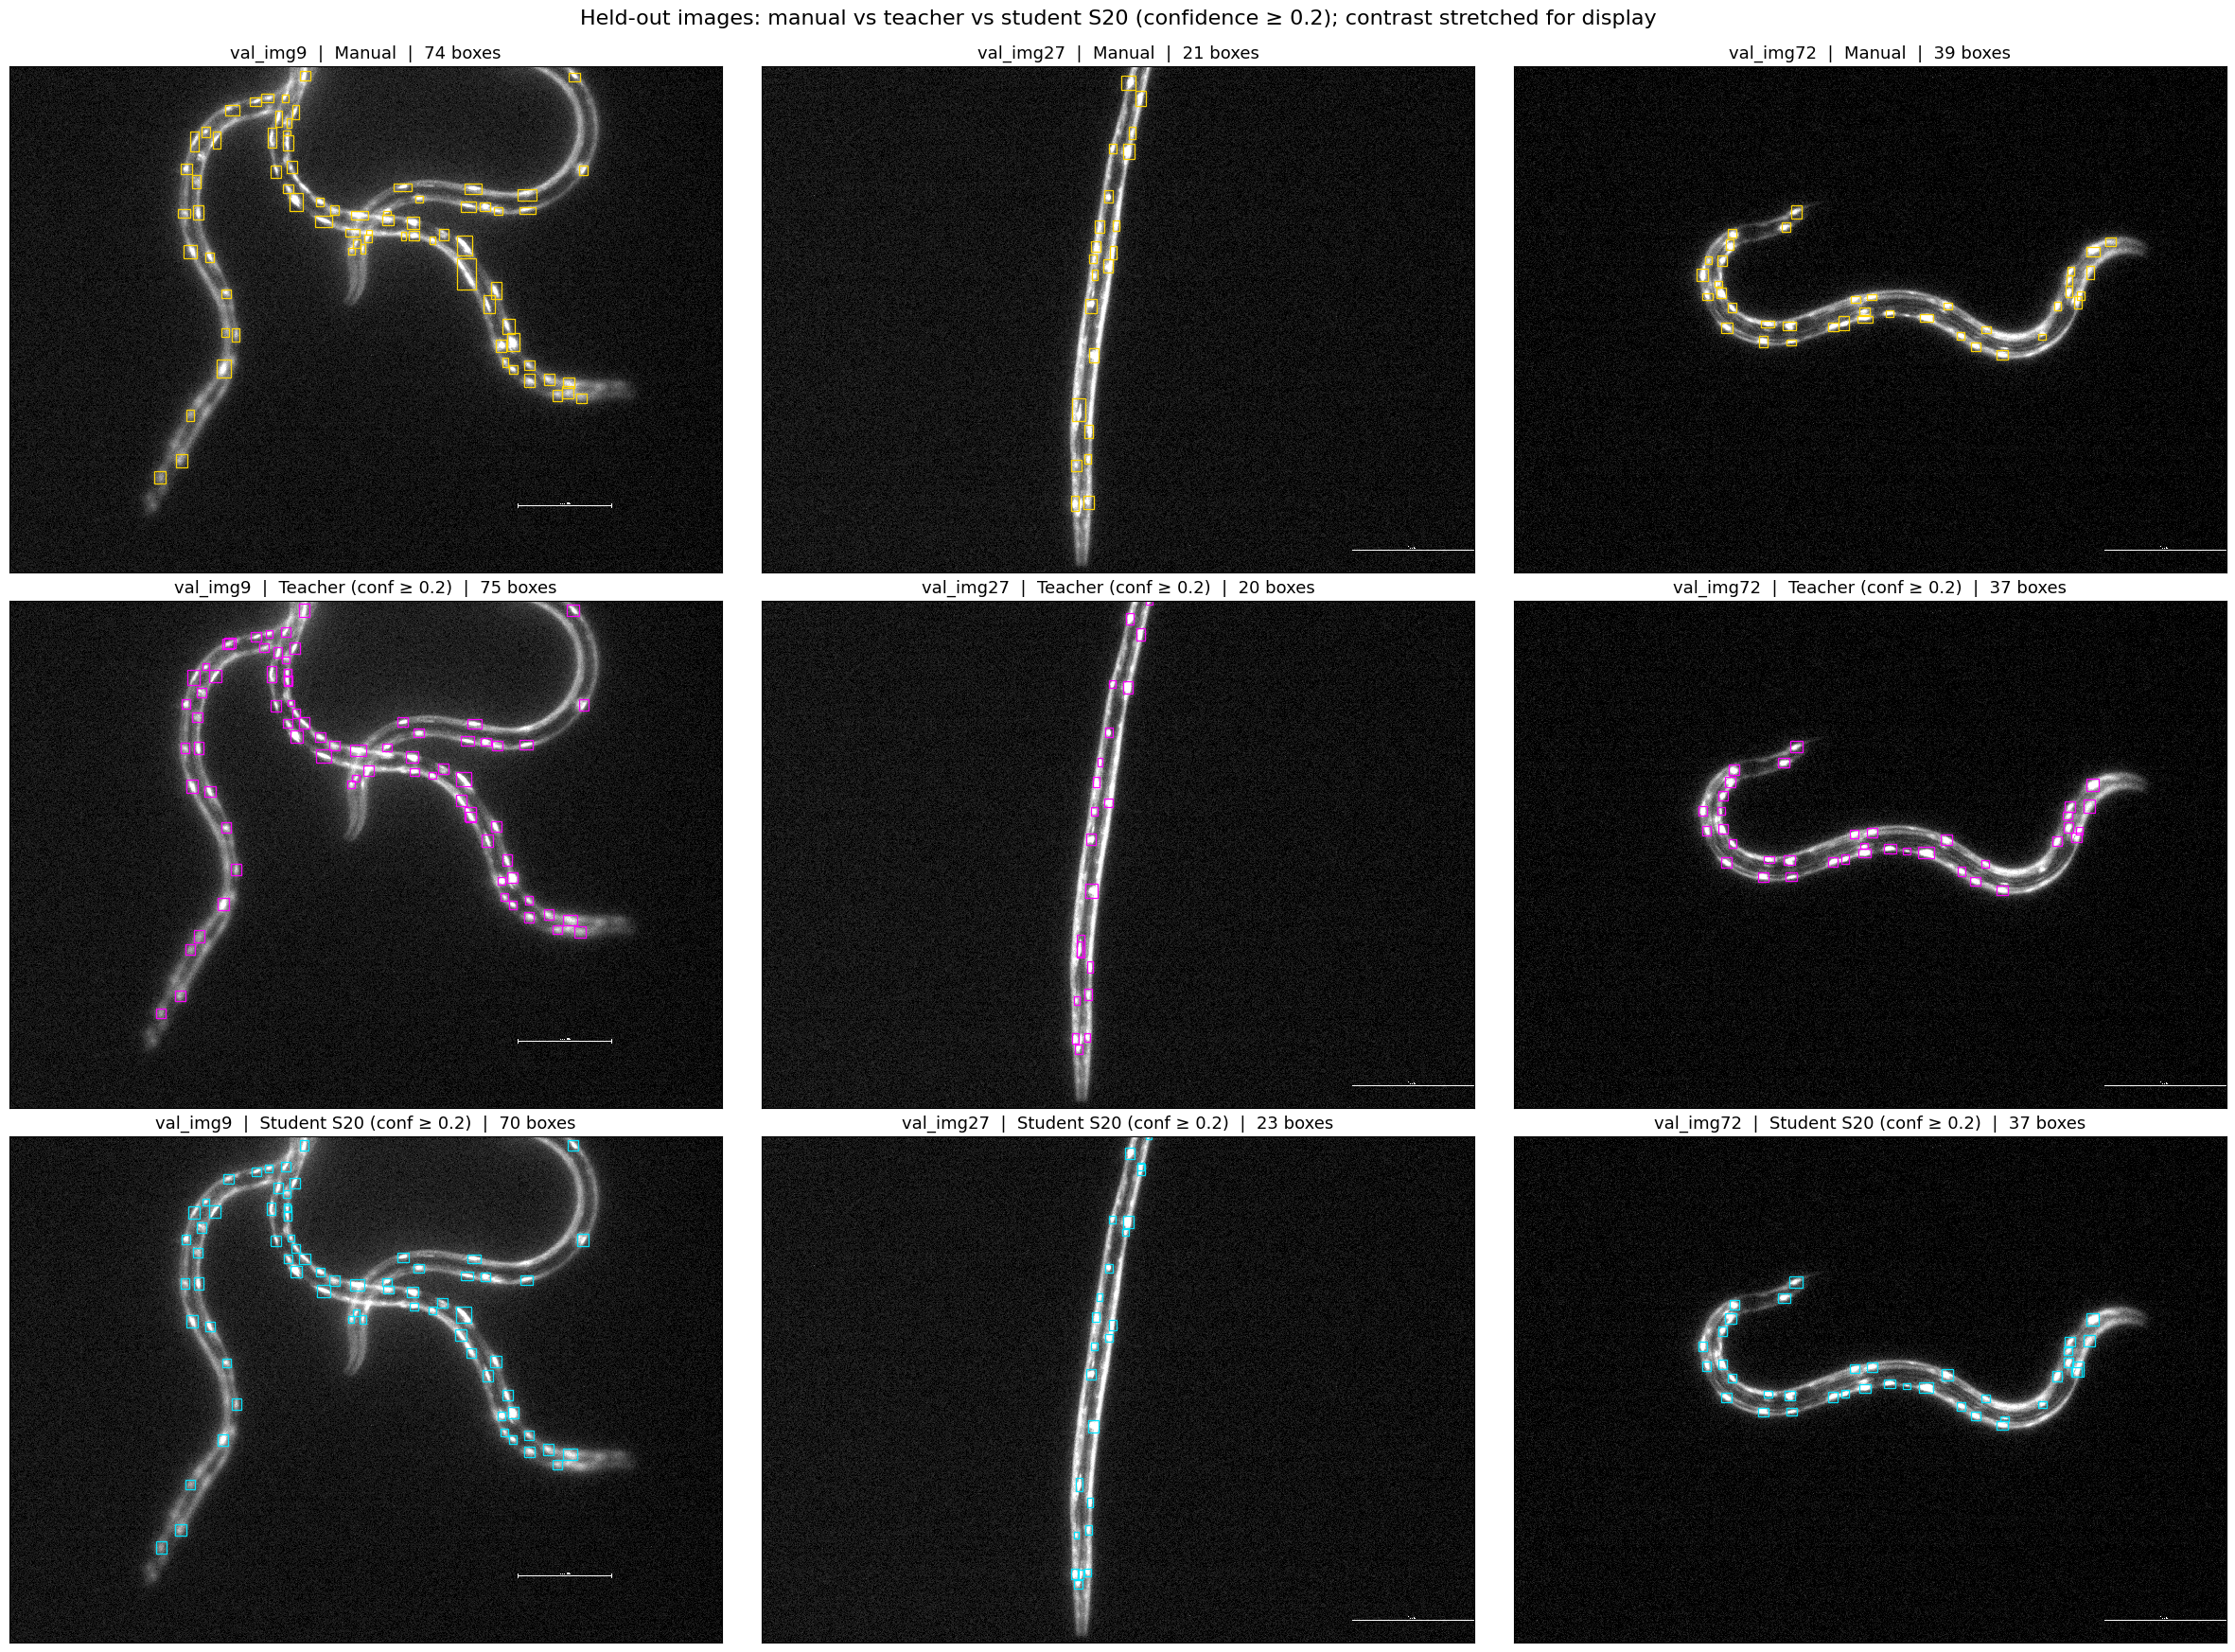

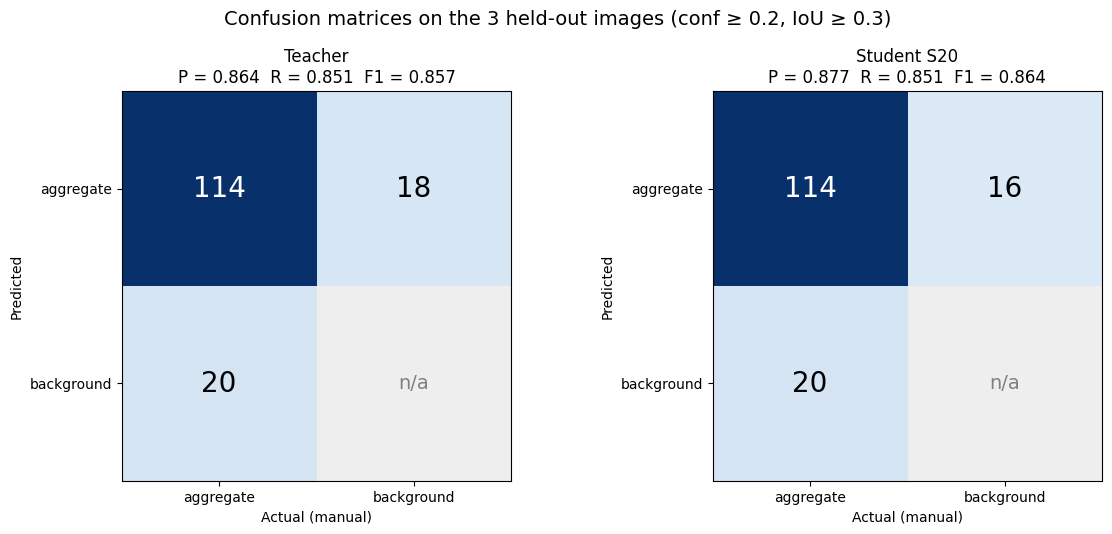

      model  conf  iou  TP  FP  FN  precision  recall    F1
    Teacher   0.2  0.3 114  18  20      0.864   0.851 0.857
Student S20   0.2  0.3 114  16  20      0.877   0.851 0.864

Saved figures and CSV in /content/drive/MyDrive/paper_results


In [3]:
# ===== SECTION 6 ONLY: held-out images with boxes (manual vs teacher vs student) + confusion matrices, all at conf 0.2 =====
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
from google.colab import drive
drive.mount('/content/drive')

import os, re, math, zipfile
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ultralytics import YOLO

# ---------------- settings (same paths as the big cell) ----------------
DRIVE       = "/content/drive/MyDrive"
PROJECT     = f"{DRIVE}/yolo_runs"
META_ZIP    = f"{DRIVE}/dataset_parts/dataset_small_meta.zip"
OUT         = f"{DRIVE}/paper_results"
TEACHER_W   = f"{PROJECT}/teacher/weights/last.pt"
STUDENT_W   = {"S05": f"{PROJECT}/student_conf0.05_nf/weights/best.pt",
               "S20": f"{PROJECT}/student_conf0.20/weights/best.pt",
               "S40": f"{PROJECT}/student_conf0.40_nf/weights/best.pt",
               "S20c": f"{PROJECT}/student_conf0.20_cont/weights/best.pt"}
STUDENT_KEY = "S20"        # <- which student to show (S05 / S20 / S40 / S20c)
CONF        = 0.20         # confidence threshold for drawing boxes and for the confusion matrices
CM_IOU      = 0.30         # IoU needed to count a prediction as a true positive (0.30 matches P30/R30; set 0.50 for the stricter version)
N_FINAL, EXPECTED_FINAL = 3, ["val_img27", "val_img72", "val_img9"]
NMS_IOU, MAX_DET = 0.6, 1000
os.makedirs(OUT, exist_ok=True)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
stem_of = lambda n: os.path.splitext(os.path.basename(n))[0]
jnum = lambda s: int(re.search(r"(\d+)(?:\.\w+)?$", s).group(1))

def parse_boxes(text):
    rows = []
    for line in text.strip().splitlines():
        p = line.split()
        if len(p) < 5: continue
        v = list(map(float, p[1:]))
        if len(v) == 4: cx, cy, w, h = v
        else:
            xs, ys = v[0::2], v[1::2]; cx, cy, w, h = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)
        rows.append((cx, cy, w, h))
    return rows

# ---------------- load the 12 manually annotated images, recover the 3 held-out ones ----------------
mz = zipfile.ZipFile(META_ZIP); mn = mz.namelist()
meta_imgs = {stem_of(n): n for n in mn if os.path.splitext(n)[1].lower() in IMG_EXT}
meta_lbls = {stem_of(n): n for n in mn if n.endswith(".txt")}
imgs, gts = {}, {}
for s in sorted(meta_imgs):
    a = cv2.imdecode(np.frombuffer(mz.read(meta_imgs[s]), np.uint8), cv2.IMREAD_COLOR); H, W = a.shape[:2]
    rows = parse_boxes(mz.read(meta_lbls[s]).decode()) if s in meta_lbls else []
    imgs[s] = a; gts[s] = np.array([[(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H] for cx, cy, w, h in rows]).reshape(-1, 4)
order = list(np.random.default_rng(0).permutation(sorted(imgs)))
final_stems = sorted(order[:N_FINAL])
assert final_stems == sorted(EXPECTED_FINAL), "held-out images differ from the earlier ones -> stop and check"
held = sorted(final_stems, key=jnum)                       # val_img9, val_img27, val_img72

# ---------------- inference (identical to the big cell: native scale, NMS 0.6, keep >= 0.001, then filter) ----------------
def predict(model, img):
    r = model.predict(img, imgsz=int(math.ceil(max(img.shape[:2]) / 32) * 32), conf=0.001, iou=NMS_IOU, max_det=MAX_DET, verbose=False)[0]
    return np.hstack([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]])

assert os.path.exists(TEACHER_W), f"teacher weights missing: {TEACHER_W}"
assert STUDENT_KEY in STUDENT_W and os.path.exists(STUDENT_W[STUDENT_KEY]), f"student weights missing for {STUDENT_KEY}"
teacher, student = YOLO(TEACHER_W), YOLO(STUDENT_W[STUDENT_KEY])
PT = {s: predict(teacher, imgs[s]) for s in held}
PS = {s: predict(student, imgs[s]) for s in held}
keep = lambda P, s: P[s][P[s][:, 4] >= CONF][:, :4]

# ---------------- FIGURE: rows = manual / teacher / student, columns = the 3 held-out images ----------------
def display(a):                                            # contrast stretch for viewing only (images are very dark); does not affect any metric
    g = a.max(axis=2).astype(np.float32); hi = max(np.percentile(g, 99.7), 1.0)
    return np.clip(g / hi, 0, 1) ** 0.6

rows_def = [("Manual", {s: gts[s] for s in held}, "#ffd600"),
            (f"Teacher (conf ≥ {CONF})", {s: keep(PT, s) for s in held}, "#ff00ff"),
            (f"Student {STUDENT_KEY} (conf ≥ {CONF})", {s: keep(PS, s) for s in held}, "#00e5ff")]
fig, axes = plt.subplots(3, 3, figsize=(24, 17.5))
for r, (label, boxes, col) in enumerate(rows_def):
    for c, s in enumerate(held):
        ax = axes[r, c]; ax.imshow(display(imgs[s]), cmap="gray", interpolation="nearest")
        for x1, y1, x2, y2 in boxes[s]:
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=col, linewidth=0.9))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{s}  |  {label}  |  {len(boxes[s])} boxes", fontsize=13)
fig.suptitle(f"Held-out images: manual vs teacher vs student {STUDENT_KEY} (confidence ≥ {CONF}); contrast stretched for display", fontsize=16, y=0.995)
plt.tight_layout()
fig.savefig(f"{OUT}/06_heldout_boxes_manual_teacher_student.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------------- CONFUSION MATRICES (detection: TP / FP / FN, greedy one-to-one matching by confidence) ----------------
def iou_mat(a, b):
    if not len(a) or not len(b): return np.zeros((len(a), len(b)))
    iw = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    ih = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = iw * ih; ar = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)

def confusion(P):
    tp = fp = fn = 0
    for s in held:
        p = P[s][P[s][:, 4] >= CONF]; p = p[np.argsort(-p[:, 4])]; g = gts[s]
        if not len(g): fp += len(p); continue
        iou = iou_mat(p[:, :4], g); used = np.zeros(len(g), bool); m = 0
        for i in range(len(p)):
            cand = np.where(used, -1.0, iou[i]); j = int(cand.argmax())
            if cand[j] >= CM_IOU: used[j] = True; m += 1
        tp += m; fp += len(p) - m; fn += len(g) - m
    return tp, fp, fn

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4)); summ = []
for ax, (name, P) in zip(axes, [("Teacher", PT), (f"Student {STUDENT_KEY}", PS)]):
    tp, fp, fn = confusion(P); pr, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1); f1 = 2 * pr * rc / max(pr + rc, 1e-9)
    summ.append(dict(model=name, conf=CONF, iou=CM_IOU, TP=tp, FP=fp, FN=fn, precision=pr, recall=rc, F1=f1))
    M = np.array([[tp, fp], [fn, np.nan]], float)           # rows = predicted, columns = actual (Ultralytics convention)
    cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("#eeeeee")
    ax.imshow(np.ma.masked_invalid(M), cmap=cmap, vmin=0, vmax=max(tp, fp, fn, 1))
    for i in range(2):
        for j in range(2):
            if np.isnan(M[i, j]): ax.text(j, i, "n/a", ha="center", va="center", fontsize=14, color="gray")
            else: ax.text(j, i, f"{int(M[i, j])}", ha="center", va="center", fontsize=20, color="white" if M[i, j] > max(tp, fp, fn, 1) / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["aggregate", "background"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["aggregate", "background"])
    ax.set_xlabel("Actual (manual)"); ax.set_ylabel("Predicted")
    ax.set_title(f"{name}\nP = {pr:.3f}  R = {rc:.3f}  F1 = {f1:.3f}", fontsize=12)
fig.suptitle(f"Confusion matrices on the 3 held-out images (conf ≥ {CONF}, IoU ≥ {CM_IOU})", fontsize=14)
plt.tight_layout(); fig.savefig(f"{OUT}/06_confusion_matrices_teacher_student.png", dpi=200, bbox_inches="tight"); plt.show()

cmdf = pd.DataFrame(summ); print(cmdf.round(3).to_string(index=False)); cmdf.to_csv(f"{OUT}/06_confusion_counts.csv", index=False)
print(f"\nSaved figures and CSV in {OUT}")